# MB4 · Rang faible et recherche d'information — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/mb4_rang_faible/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | MB4.1 à MB4.4 | Les exercices papier (vérification) | ✏️ | | |
| A | MB4.8 | La factorisation de rang C F : les colonnes pivots de M et les lignes non nulles de sa forme échelonnée réduite · `rank_factorization` | 🔨 | ★ | 20 |
|  | MB4.9 | Les points de Borda de classements complets, et le MRR exact d'un ordre tiré au hasard, en fractions · `borda_scores`, `random_ranking_mrr` | 🔨 | ★★ | 25 |
| B | MB4.10 | Prédire le MRR d'un ordre tiré au hasard parmi 10, 100 puis 1 000 candidats, puis le simuler et le comparer à H_n/n | 🔮 | ★ | 15 |
|  | MB4.11 | Les courbes de saturation x ↦ x(k₁ + 1)/(x + k₁) de k₁ = 0 à l'infini, et ce que la normalisation par la longueur leur fait | 🎨 | ★ | 15 |
| C | MB4.12 | Chasse à l'erreur : C pris dans la forme réduite au lieu de M, un classement lu comme la liste des rangs des candidats, un poids de rareté écrit ln(n/N) | 🐛 | ★ | 15 |
| D | MB4.13 | Défi : retrouver le rang caché de cinq tableaux bruités, cinq fois sur cinq, par leurs valeurs singulières | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : les ventes de quatre boulangeries, les relevés de stations météo, les ingrédients d'un carnet de recettes, et trois jurys d'un concours de pâtisserie.
- Écrire les trois fonctions de `mymath/ranks.py` (`rank_factorization`, `borda_scores`, `random_ranking_mrr`) et les tester.
- Prédire puis simuler le MRR d'un ordre tiré au hasard, tracer des courbes de saturation, corriger trois erreurs classiques, et relever un défi.

**Rappel express.** Une matrice $(m, n)$ de rang $r$ est un produit $\mathbf{C}\mathbf{F}$ : $\mathbf{C}$ ses $r$ colonnes pivots, $\mathbf{F}$ les $r$ lignes non nulles de sa forme échelonnée réduite ; $r(m + n)$ nombres stockés, $r(m + n - r)$ libres ; $\mathbf{C}(\mathbf{F}\mathbf{x})$ coûte $r(m + n)$ multiplications. L'énergie $\lVert\mathbf{M}\rVert_F^2 = \sum_is_i^2$ ; le rang effectif à $\tau$, le plus petit $r$ dont la part atteint $\tau$ ; le rang stable $\sum_is_i^2/s_1^2$. La surprise $-\ln\frac nN$, le poids corrigé $\ln\frac{N - n + 1/2}{n + 1/2}$. La saturation $s(x) = \frac{x(k_1 + 1)}{x + k_1}$, et la normalisation $\nu = 1 - b + b\ell$, qui remplace $k_1$ par $k_1\nu$. Borda : $n - j$ points au rang $j$ ; la somme des $\frac{1}{c + \text{rang}}$. Pour un ordre tiré au hasard, $P(R = j) = \binom{n - j}{q - 1}\big/\binom nq$.

## Partie 0 · Vérifier tes exercices papier (✏️ MB4.1 à MB4.4)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (« a number » sans décimales : la valeur exacte, ce calcul tombe juste) ;
- une fraction irréductible entre guillemets, `"5/8"` ;
- une liste `[0.2, -1]`, dans l'ordre que dit la question ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ; une matrice de valeurs exactes peut contenir des fractions entre guillemets.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (SymPy for the reduced form and the equation of MB4.4 f,
# exact fractions where the calculation is exact, math elsewhere)
import math
from fractions import Fraction as F

import numpy as np
import sympy as sp


def floats(values):
    """A number, a vector or a matrix (fractions, SymPy, NumPy) as a float or nested lists of floats (-0.0 written 0.0)."""
    return (np.round(np.asarray(values, dtype=float), 12) + 0.0).tolist()


# MB4.1: four bakeries (Port, Gare, Halles, Moulin) x five products, in tens; G = [[1, 1], [0, 2]]
M_1 = sp.Matrix([[20, 6, 16, 12, 8], [8, 10, 14, 20, 7], [12, 4, 10, 8, 5], [16, 2, 10, 4, 5]])
G_1 = sp.Matrix([[1, 1], [0, 2]])
RREF_1, PIVOTS_1 = M_1.rref()
R_1 = len(PIVOTS_1)
C_1, F_1 = M_1[:, list(PIVOTS_1)], RREF_1[:R_1, :]
assert C_1 * F_1 == M_1


def swapped_coefficients_1(F_):
    """The classic error of b): in the columns that are not pivots, the coefficients of the two pivot columns swapped."""
    W = F_.copy()
    for j in range(W.cols):
        if j not in PIVOTS_1:
            W[0, j], W[1, j] = F_[1, j], F_[0, j]
    return W


def stored(m, n, r):
    return r * (m + n)


def free(m, n, r):
    return r * (m + n - r)


# MB4.2: a 60 x 450 table (60 stations, 450 days), singular values 320, 150, 60, 15, then 56 times 3
S_2 = [320, 150, 60, 15] + [3] * 56
ROWS_2, COLS_2 = 60, 450
ENERGY_2 = sum(s * s for s in S_2)


def share_2(r, values=S_2, power=2):
    """The share of the first r singular values (power 1: the classic error, values instead of squares)."""
    return sum(s ** power for s in values[:r]) / sum(s ** power for s in values)


def effective_rank_2(level=0.99, power=2):
    return next(r for r in range(1, len(S_2) + 1) if share_2(r, power=power) >= level)


RANK_2 = effective_rank_2()


# MB4.3: a notebook of N = 80 recipe cards; orange blossom in 4, eggs in 62; the saturation with k1 = 2
N_3, ORANGE_3, EGGS_3, K1_3 = 80, 4, 62, 2


def weight_3(n, N=N_3, half=F(1, 2)):
    """The corrected weight ln((N − n + half)/(n + half)); half = 0 or 1: the classic errors."""
    return math.log((N - n + half) / (n + half))


def variant_3(n, N=N_3):
    return math.log((N + 1) / (n + F(1, 2)))


def saturation_3(x, k1=K1_3):
    return F(x * (k1 + 1)) / (x + k1)


def normalised_3(x, ell, b, k1=K1_3, swap=False):
    """x (k1 + 1) / (x + k1 nu), nu = 1 − b + b ell (swap: the classic error nu = b + (1 − b) ell)."""
    nu = b + (1 - b) * ell if swap else 1 - b + b * ell
    return F(x * (k1 + 1)) / (x + k1 * nu)


# MB4.4: marks /20 of A, B, C, D, E by the juries of the chefs, of the public and of the press; c = 2 and c = 10
MARKS_4 = [[17, 15, 12, 11, 8], [16, 14, 8, 13, 11], [6, 14, 18, 10, 13]]
N_4 = 5


def ranks_4(marks=MARKS_4):
    """The rank of each candidate for each jury: 1 + the number of higher marks (no ties)."""
    return [[1 + sum(other > mine for other in row) for mine in row] for row in marks]


def rank_sums_4():
    return [sum(col) for col in zip(*ranks_4())]


def borda_4(start=0):
    """n − j points at rank j (start=1: the classic error n − j + 1)."""
    return [sum(N_4 - j + start for j in col) for col in zip(*ranks_4())]


def rrf_4(c, mode="sum"):
    """The sum of the 1/(c + rank), exact; mode "times": 1/(c rank), "mean": divided by 3 (the classic errors)."""
    out = []
    for col in zip(*ranks_4()):
        total = sum(F(1, c * j) if mode == "times" else F(1, c + j) for j in col)
        out.append(total / 3 if mode == "mean" else total)
    return out


def rrf_rounded_terms_4(c):
    """The classic error: each term 1/(c + j) rounded to 4 decimals before the sum."""
    return [round(sum(round(1 / (c + j), 4) for j in col), 4) for col in zip(*ranks_4())]


def rescaled_4(jury):
    """The marks with those of one jury multiplied by 5 (marked out of 100)."""
    return [[5 * x for x in row] if k == jury else row for k, row in enumerate(MARKS_4)]


def tie_4(drop_last_of_a=False):
    """The c > 0 where A and B have the same sum of the 1/(c + rank) (drop_last_of_a: A's fifth place forgotten)."""
    c = sp.symbols("c", positive=True)
    ranks = list(zip(*ranks_4()))
    a = [j for j in ranks[0] if not (drop_last_of_a and j == max(ranks[0]))]
    solutions = sp.solve(sp.together(sum(1 / (c + j) for j in a) - sum(1 / (c + j) for j in ranks[1])), c)
    assert len(solutions) == 1
    return float(solutions[0])

**Ex MB4.1 — Les ventes de quatre boulangeries sur cinq produits : le rang, la factorisation par les colonnes pivots, une seconde factorisation (CG)(G⁻¹F), et les nombres stockés ou libres**

In [3]:
wbm.record("MB4.1a", R_1, mistakes={"le rang compte les colonnes indépendantes, pas les lignes du tableau": M_1.rows,
                     "une colonne qui est une combinaison d'autres colonnes n'ajoute aucune direction": M_1.cols})
wbm.record("MB4.1b", floats(F_1), decimals=6,
           mistakes={"la ligne i de F porte les coordonnées sur la i-ième colonne pivot, dans chaque colonne de F":
                         floats(swapped_coefficients_1(F_1)),
                     "F ne garde que les r lignes non nulles de la forme échelonnée réduite": floats(RREF_1)})
wbm.record("MB4.1c", floats(C_1 * G_1), decimals=6,
           mistakes={"la colonne j de C G combine les colonnes de C avec les coefficients de la colonne j de G":
                         floats(C_1 * G_1.T),
                     "la seconde factorisation multiplie C par G, et F par l'inverse de G": floats(C_1 * G_1.inv())})
wbm.record("MB4.1d", floats(G_1.inv() * F_1), decimals=6,
           mistakes={"F se multiplie à gauche par l'inverse de G, pas par G": floats(G_1 * F_1),
                     "l'inverse d'une matrice 2 × 2 se vérifie : G G⁻¹ = I": floats(G_1.inv().T * F_1)})
wbm.record("MB4.1e", stored(4, 5, R_1), mistakes={"C et F stockent r colonnes de m nombres et r lignes de n nombres : ni les m n nombres du tableau, "
                     "ni des valeurs singulières": R_1 * (4 + 5 + 1),
                     "il faut r colonnes dans C et r lignes dans F": 4 + 5,
                     "C a r colonnes de m nombres et F a r lignes de n nombres : on additionne": R_1 * 4 * 5})
wbm.record("MB4.1f", free(4, 5, R_1), mistakes={"l'identité des colonnes pivots fixe r² nombres de F, pas r": R_1 * (4 + 5 - 1),
                     "C compte aussi : ses m r nombres sont libres": R_1 * (5 - R_1)})
wbm.record("MB4.1g", [stored(120, 45, 3), free(120, 45, 3)], mistakes={"l'identité des colonnes pivots fixe r² nombres de F, pas r": [stored(120, 45, 3), 3 * (120 + 45 - 1)],
                     "C et F stockent r colonnes de m nombres et r lignes de n nombres : ni les m n nombres du tableau, "
                     "ni des valeurs singulières": [3 * (120 + 45 + 1), 3 * (120 + 45 + 1 - 3)]})

WBM_ANSWER {"hash": "a58ee2db06a5f4e0a8561770fb2e85de41b93641f0e3daa5073d1c5168424198", "id": "MB4.1a", "kind": "int", "magnitude": 0, "mistakes": {"9f9ba6d330c1f6f7521c974927a8c45612c3eb3ca254a0ae8c2b0c95236d7103": "le rang compte les colonnes indépendantes, pas les lignes du tableau", "aa2d3a735341603013dc279d9425d841be0732e574cb83a2f05d39ba25097567": "une colonne qui est une combinaison d'autres colonnes n'ajoute aucune direction"}, "sign": 1}
📝 Ex MB4.1a : réponse enregistrée (int).
WBM_ANSWER {"array_rounded": {"1": "72f2a4ca15c75cbcf34b36367ed8d847583ecf89f485c01d6af4bfe47a660c31"}, "decimals": 6, "element_coarse": [["373b65ac6dc1577e3225e8eaa0012d5522b148001389f78433c0f0bceb9a7f92"], ["07192ce0ceecfff456fe55bd0fd35217641b90b7f3fabaeef46384c4f61e2d88"], ["525b0ce3b87ca56c50f5e3b1e6af7c3f24414141166af0d0f434ac641ff38e43"], ["6805c4d1e92b18ebec99a60c926abbf0ea9f67795715dd7324532acaf0de5bc0"], ["f2c5ecfa7082e8396b894b4364c908ca2190484596fbf2891ed9a21dadb73cad"], ["5a8ef9442d43246943

**Ex MB4.2 — Un tableau de relevés de stations météo donné par ses valeurs singulières : énergie captée, rang effectif à 99 %, rang stable, puis le coût de C(Fx) et de (CF)x pour un et pour mille vecteurs**

In [4]:
wbm.record("MB4.2a", ENERGY_2, mistakes={"l'énergie est la somme des carrés des valeurs singulières": sum(S_2),
                     "les 56 petites valeurs singulières comptent aussi dans l'énergie": sum(s * s for s in S_2[:4])})
wbm.record("MB4.2b", share_2(2), decimals=4,
           mistakes={"l'énergie compte les carrés des valeurs singulières": share_2(2, power=1),
                     "le total compte toutes les valeurs singulières, les 56 petites comprises":
                         share_2(2, values=S_2[:4]),
                     "la part des deux premières additionne les carrés des deux premières valeurs": share_2(1)})
wbm.record("MB4.2c", RANK_2, mistakes={"le rang effectif à 99 % est le plus petit r dont la part atteint 0,99 : on s'arrête dès qu'elle "
                     "l'atteint": RANK_2 + 1,
                     "l'énergie compte les carrés des valeurs singulières": effective_rank_2(power=1)})
wbm.record("MB4.2d", math.sqrt(sum(s * s for s in S_2[RANK_2:])), decimals=2,
           mistakes={"‖·‖_F est la racine de la somme des carrés oubliés": float(sum(s * s for s in S_2[RANK_2:])),
                     "en norme de Frobenius, l'erreur compte toutes les valeurs singulières oubliées, pas seulement la plus "
                     "grande": float(S_2[RANK_2]),
                     "la quatrième valeur singulière est oubliée elle aussi": math.sqrt(sum(s * s for s in S_2[RANK_2 + 1:]))})
wbm.record("MB4.2e", ENERGY_2 / S_2[0] ** 2, decimals=3,
           mistakes={"le rang stable est un rapport de carrés": sum(S_2) / S_2[0],
                     "le rang stable divise l'énergie par le carré de la plus grande valeur singulière":
                         S_2[0] ** 2 / ENERGY_2})
wbm.record("MB4.2f", RANK_2 * (ROWS_2 + COLS_2), mistakes={"C(Fx) ne forme jamais le produit C F : d'abord F x, puis C fois ce vecteur": ROWS_2 * COLS_2 * RANK_2,
                     "la matrice factorisée n'est pas appliquée comme une matrice pleine : F x, puis C fois ce vecteur":
                         ROWS_2 * COLS_2})
wbm.record("MB4.2g", ROWS_2 * COLS_2 * RANK_2 + ROWS_2 * COLS_2, mistakes={"former C F coûte aussi des multiplications": ROWS_2 * COLS_2,
                     "après avoir formé C F, il reste à l'appliquer à x": ROWS_2 * COLS_2 * RANK_2})
wbm.record("MB4.2h", [1000 * RANK_2 * (ROWS_2 + COLS_2), ROWS_2 * COLS_2 * RANK_2 + 1000 * ROWS_2 * COLS_2], mistakes={"C F ne se forme qu'une fois, puis s'applique aux mille vecteurs":
                         [1000 * RANK_2 * (ROWS_2 + COLS_2), 1000 * (ROWS_2 * COLS_2 * RANK_2 + ROWS_2 * COLS_2)],
                     "chacun des mille vecteurs demande son propre F x et son propre C(F x)":
                         [RANK_2 * (ROWS_2 + COLS_2), ROWS_2 * COLS_2 * RANK_2 + 1000 * ROWS_2 * COLS_2]})

WBM_ANSWER {"hash": "3238c1ca8e8d611e01b4a6abe2015caa1f5726f4ce21a396d0ceab7f9fa59b6b", "id": "MB4.2a", "kind": "int", "magnitude": 5, "mistakes": {"bcaf2305eeae98f450d613bdae8e9f3f3e033ee2c1e50f8546f29ea8cc7ce41b": "les 56 petites valeurs singulières comptent aussi dans l'énergie", "fcf5860a1f9f17a54a3f7cbd51b3d2b40ad7480ab17aacd0d0964a394f75ba8d": "l'énergie est la somme des carrés des valeurs singulières"}, "sign": 1}
📝 Ex MB4.2a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["2caafa6becfe35ee8811a39f0bcdb32f4d664e9a02265cf5b48cf709da79fb9e"], "1": ["7a877766d5e4a018ad18fd2049ff6e9dfdb14647d9950e9c404d6dc67e4a7d27"]}, "coarser": {"2": ["837d318ba51d6716668a79512f34644d58989b905cc0423f07afe78d9e5c68bb"]}, "decimals": 4, "hash": "c5b7f4005be5bb0d48cf8ace93cf9fc4ad7a922ae1d25e8f8dd2af01b63cf9bc", "hash_coarse": "3727bfe91ab7ff0b2dfc97d9c3994c36d732b53da3c401c928f04c54466afe86", "id": "MB4.2b", "kind": "float", "magnitude": -1, "mistakes": {"4256533a503dc383858b22315f12d7

**Ex MB4.3 — Les ingrédients d'un carnet de recettes : surprise, cote, poids corrigé par ½ et son signe, la variante toujours positive, puis la saturation et la normalisation d'une mention répétée**

In [5]:
wbm.record("MB4.3a", -math.log(F(ORANGE_3, N_3)), decimals=4,
           mistakes={"une surprise est positive : −ln p, avec p = n/N plus petit que 1": math.log(F(ORANGE_3, N_3)),
                     "le logarithme est népérien": -math.log10(F(ORANGE_3, N_3)),
                     "le logarithme est népérien, pas en base 2": -math.log2(F(ORANGE_3, N_3))})
wbm.record("MB4.3b", F(ORANGE_3, N_3 - ORANGE_3), kind="fraction", simplified=True,
           mistakes={"la cote divise le nombre de fiches qui contiennent l'ingrédient par le nombre de celles qui ne le "
                     "contiennent pas": F(ORANGE_3, N_3),
                     "la cote de présence est n/(N − n), pas son inverse": F(N_3 - ORANGE_3, ORANGE_3)})
wbm.record("MB4.3c", weight_3(ORANGE_3), decimals=4,
           mistakes={"le poids corrigé met N − n + ½ au numérateur": -weight_3(ORANGE_3),
                     "la correction ajoute ½ à chaque compte": weight_3(ORANGE_3, half=0),
                     "la correction ajoute ½, pas 1": weight_3(ORANGE_3, half=1)})
wbm.record("MB4.3d", weight_3(EGGS_3), decimals=4,
           mistakes={"le poids corrigé met N − n + ½ au numérateur": -weight_3(EGGS_3),
                     "la correction ajoute ½ à chaque compte": weight_3(EGGS_3, half=0),
                     "la correction ajoute ½, pas 1": weight_3(EGGS_3, half=1)})
wbm.record("MB4.3e", next(n for n in range(N_3 + 1) if weight_3(n) < 0), mistakes={"pour n = N/2, le poids corrigé est nul : nul n'est pas négatif":
                         next(n for n in range(N_3 + 1) if weight_3(n) <= 0),
                     "la question demande le plus petit n pour lequel le poids est négatif":
                         next(n for n in range(N_3 + 1) if weight_3(n) <= 0) - 1})
wbm.record("MB4.3f", variant_3(EGGS_3), decimals=4,
           mistakes={"réduis au même dénominateur : n + ½ + N − n + ½ = N + 1": math.log(N_3 / (EGGS_3 + F(1, 2))),
                     "la variante garde le ½ au dénominateur": math.log((N_3 + 1) / EGGS_3)})
wbm.record("MB4.3g", floats([saturation_3(x) for x in (1, 2, 10)]), decimals=4,
           mistakes={"la saturation n'est pas le compte brut : elle plafonne": [1.0, 2.0, 10.0],
                     "s(x) = x(k₁ + 1)/(x + k₁) : le compte x est aussi au numérateur":
                         floats([F(K1_3 + 1, x + K1_3) for x in (1, 2, 10)])})
wbm.record("MB4.3h", (saturation_3(10) - saturation_3(9)) / (saturation_3(1) - saturation_3(0)), kind="fraction", simplified=True,
           mistakes={"la dixième mention, c'est ce qu'elle ajoute : s(10) − s(9)": saturation_3(10) / saturation_3(1),
                     "la dixième mention fait passer de 9 à 10 mentions": saturation_3(11) - saturation_3(10)})
wbm.record("MB4.3i", floats([normalised_3(3, 2, F(1, 4)), normalised_3(3, 2, F(1, 2))]), decimals=4,
           mistakes={"une fiche plus longue que la moyenne voit sa saturation baisser": floats([saturation_3(3)] * 2),
                     "le facteur est 1 − b + b ℓ : c'est b qui pèse sur ℓ":
                         floats([normalised_3(3, 2, F(1, 4), swap=True), normalised_3(3, 2, F(1, 2), swap=True)])})

WBM_ANSWER {"coarse_any": {"0": ["9984cb446c2b6ae86f2a00a1e3d552083a06e4f75d99f27b780b716b20205cab"]}, "coarser": {"1": ["e4b3039dcd6febe5bfa0be69355f71222dddb64e28a7c0012ee462ad1be1088e"], "2": ["0e4a16163348b2420f348c9a6c23f3baa3f8a98f576db0bc4a91f535198ba793"]}, "decimals": 4, "hash": "1edb83bc7f5c61f396f7bc7ea3b57decce9838a9e8b5f7942a9f03cf8d79a2a0", "hash_coarse": "74860ad5390299985d900e4d357266175aa3272a307401f20c8750df3ff21ef2", "id": "MB4.3a", "kind": "float", "magnitude": 0, "mistakes": {"134ec6345a7f71baa5ae4bb2eae3127dffa02445554a76127df9f3674866f74e": "une surprise est positive : −ln p, avec p = n/N plus petit que 1", "2b9671b6ffbc92bee47449f504b0a778304f8dba804b1d5e2eae5f60f17634cc": "le logarithme est népérien, pas en base 2", "e06ba6a2b4d49f6b80e6590a21c9d07ce283537f09cd4ffbf02fc1c1a648980c": "le logarithme est népérien"}, "sign": 1}
📝 Ex MB4.3a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "9f1cb9c97c0fb72e49529d82811650a621fc7f5bdfd1fdef4a65a05ad54a41

**Ex MB4.4 — Trois jurys classent cinq pâtissiers : les points de Borda, la somme des 1/(c + rang) pour c = 2 et c = 10, et la somme des notes qui change de gagnant quand un jury passe de 20 à 100 points**

In [6]:
wbm.record("MB4.4a", borda_4(), mistakes={"un rang j rapporte n − j points : la première place rapporte le plus": rank_sums_4(),
                     "la dernière place rapporte 0 point": borda_4(start=1)})
wbm.record("MB4.4b", floats(rrf_4(2)), decimals=4,
           mistakes={"garde 6 décimales dans chaque terme 1/(c + j), et n'arrondis que la somme": rrf_rounded_terms_4(2),
                     "c s'ajoute au rang, il ne le multiplie pas": floats(rrf_4(2, mode="times")),
                     "la fusion additionne les contributions des trois jurys, elle ne les moyenne pas":
                         floats(rrf_4(2, mode="mean"))})
wbm.record("MB4.4c", floats(rrf_4(10)), decimals=4,
           mistakes={"garde 6 décimales dans chaque terme 1/(c + j), et n'arrondis que la somme": rrf_rounded_terms_4(10),
                     "c s'ajoute au rang, il ne le multiplie pas": floats(rrf_4(10, mode="times")),
                     "la fusion additionne les contributions des trois jurys, elle ne les moyenne pas":
                         floats(rrf_4(10, mode="mean"))})
wbm.record("MB4.4d", [sum(col) for col in zip(*MARKS_4)], mistakes={"la question demande la somme des trois notes, pas leur moyenne":
                         floats([F(sum(col), 3) for col in zip(*MARKS_4)]),
                     "on additionne les notes, pas les rangs": rank_sums_4()})
wbm.record("MB4.4e", [sum(col) for col in zip(*rescaled_4(2))], mistakes={"seul le jury de la presse change d'échelle": [5 * sum(col) for col in zip(*MARKS_4)],
                     "c'est le jury de la presse qui passe sur 100": [sum(col) for col in zip(*rescaled_4(0))]})
wbm.record("MB4.4f", tie_4(), decimals=6,
           mistakes={"A reçoit aussi la contribution de sa cinquième place": tie_4(drop_last_of_a=True),
                     "c est positif : vérifie les signes quand tu développes": -tie_4()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["7fbcfc306b838b9fb4f032a5cd2f0491dc01d0e3078e653e1376b6ef0082fad9", "cf8201d4a3819e5b69e2fa4020912fa49d2d9875b7204a4764923054c28d66dc", "6c175f899080dfce4650c7342e000e58de8e7da159335428fa66c7923b73fa7a", "66a715ccd6b401cf7b0767924d03f6ee3e168133c6667e20f7d46b33d41048d1", "b65761f9e06331e930efc8d6abf25fdf5ce92fa4f86dc7a457e78a77fafee39e"], "hash": "760b1430725d1a22d95b7141f34627858de207a592bf7042e557cd0fd9c88c07", "id": "MB4.4a", "integer": true, "kind": "array", "mistakes": {"77daacca4973caecffd6f4023feb694d5adba5ea6dc039d5ade89d33690b95a8": "la dernière place rapporte 0 point", "ebca9e3341345b127c9e6f06327ca610116d3b00f1e782435b1f3e0eccf88c5b": "un rang j rapporte n − j points : la première place rapporte le plus"}, "shape": [5]}
📝 Ex MB4.4a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["e6a1442f77b109cf6801c6faa7e24610e33cec17ebbfdc88fd29238d4d7796e8"], ["d7ec2334efae33f7aee863756e6330472f8a6563

## Partie A · Ta librairie : la factorisation de rang, les points de Borda et le MRR d'un ordre au hasard

Fiche §1, §5 et §6. Les trois fonctions de `mymath/ranks.py`, leurs tests, et un usage de chacune. La cellule de données ci-dessous recopie les données des exercices papier.

In [7]:
# Tools of the notebook (parts A to D)
import math
import re
import time

import matplotlib.pyplot as plt
import numpy as np

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, run_pytest_group, verdict

TEST_MB4 = "tests/test_mb4_ranks.py"               # the tests of mymath/ranks.py
REF = wbm.load_mymath("ref", alias="mymath_ref")  # the reference: the checks of the hidden cases rely on it
ref_ranks = REF.ranks


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())[:160]
    except (TypeError, ValueError):
        return repr(value)[:160]


def check_answer(ex_id, value, hint=None):
    """wbm.check(ex_id, value, computed=True). For a list that holds True or False, the message gives only how many
    elements are right, not the place of the first wrong one (it would let you guess the booleans one by one).
    hint(value), when given, may return a targeted « Piste » for a wrong answer (None otherwise)."""
    holds_bool = isinstance(value, (list, tuple)) and any(isinstance(v, (bool, np.bool_)) for v in value)
    if not holds_bool and hint is None:
        return wbm.check(ex_id, value, computed=True)
    result = wbm.check(ex_id, value, computed=True, quiet=True)
    message = result.message
    if holds_bool:
        for cut in (" Le premier faux est le ", " Premier élément faux à l'indice "):
            message = message.split(cut)[0]
    if hint is not None and result.status not in ("correct", "pending", "unknown") and "Piste" not in message:
        try:
            extra = hint(value)
        except Exception:  # noqa: BLE001 - an odd answer: no targeted hint
            extra = None
        if extra:
            message = f"{message} Piste : {extra}"
    icon = {"correct": "✅", "pending": "⏳", "unknown": "❓"}.get(result.status, "❌")
    print(f"{icon} Ex {ex_id} : {message}")
    return result


def passes(ex_id, value):
    """True when value is the hidden answer ex_id (wbm.check, computed=True, nothing printed)."""
    try:
        return bool(wbm.check(ex_id, value, computed=True, quiet=True).passed)
    except Exception:  # noqa: BLE001 - an odd value is not the answer
        return False


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def as_floats(value):
    """value as a float array, or None when it is not an array of numbers."""
    try:
        return np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding (no error for an odd
    got)."""
    arr = as_floats(got)
    want = np.asarray(want, dtype=float)
    return arr is not None and arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol,
                                                                            equal_nan=True))


def line_with(ax, xs, ys, rtol=1e-7, atol=1e-9):
    """True when a line of ax has exactly the abscissas xs and the ordinates ys."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        x, y = np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)
        if x.shape == xs.shape and y.shape == ys.shape and np.allclose(x, xs, rtol=rtol, atol=atol) \
                and np.allclose(y, ys, rtol=rtol, atol=atol, equal_nan=True):
            return True
    return False


def call_safely(label, function, *args, **kwargs):
    """function(*args, **kwargs); an error of the learner's code becomes one ❌ line naming the call (StopCheck)."""
    try:
        return function(*args, **kwargs)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the call
        print(f"❌ {label} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        raise StopCheck from None


# The data of the paper exercises (02_exercices.md)
M_1 = np.array([[20.0, 6, 16, 12, 8], [8, 10, 14, 20, 7], [12, 4, 10, 8, 5], [16, 2, 10, 4, 5]])   # MB4.1: the sales (in
#   tens) of the bakeries Port, Gare, Halles, Moulin (rows) for baguettes, croissants, pains de campagne, pains au
#   chocolat, tartelettes (columns)
S_2 = np.array([320.0, 150.0, 60.0, 15.0] + [3.0] * 56)     # MB4.2: the singular values of the 60 x 450 table
RANKINGS_4 = np.array([[0, 1, 2, 3, 4], [0, 1, 3, 4, 2], [2, 1, 4, 3, 0]])   # MB4.4: the rankings of the juries of the
#   chefs, of the public and of the press, best first (the pastry cooks A, B, C, D, E numbered 0 to 4)
for _array in (M_1, S_2, RANKINGS_4):
    _array.setflags(write=False)   # read only: a change in place raises an error at the line that does it

### Ex MB4.8 — La factorisation de rang C F : les colonnes pivots de M et les lignes non nulles de sa forme échelonnée réduite · `rank_factorization` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la factorisation de rang par les colonnes pivots, puis retrouver MB4.1 et voir le rôle de la tolérance sur un tableau mesuré.  
**Prérequis :** fiche §1 ; M09a (`rref`), M12a (colonnes pivots, rang numérique) ; Ex MB4.1 · **mymath :** `ranks.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en MB3). Ouvre ta copie `mon_travail/mymath/ranks.py`, lis la docstring du module (ses conventions, et ce qui est permis) puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.ranks.<nom>` (par exemple `mymath.ranks.rank_factorization(M)`), ou donne-leur un nom court (`rank_factorization = mymath.ranks.rank_factorization`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import math`, `from fractions import Fraction` et `import numpy as np`, et `from .matrices import rref` si tu reprends ton `rref` de M09a (sinon, recopie-le dans une fonction privée `_rref`). NumPy est permis (`@` compris), mais rien de `np.linalg`, ni SciPy (`scipy.linalg`, `scipy.stats.rankdata`), ni SymPy : les tests comparent tes résultats aux leurs, et un test lit ton module ; dans `borda_scores`, ni `np.argsort` ni `np.lexsort`. Les candidats sont numérotés à partir de 0, un rang commence à 1 ; ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `rank_factorization(M, tol=1e-10)` (fiche §1), en suivant sa docstring : contrôle $\mathbf{M}$ (un tableau 2-D non vide de nombres finis) et `tol` (un réel $\ge 0$, ni `nan` ni un booléen) ; réduis une copie en flottants comme le fait `rref` de M09a (tu peux importer `rref` de `.matrices`, ou le recopier dans une fonction privée `_rref`), et garde ses colonnes pivots ; $\mathbf{C}$ est faite des colonnes pivots de $\mathbf{M}$ elle-même, $\mathbf{F}$ des $r$ premières lignes de la forme réduite.

**L'usage.** Le notebook fournit `M_8`, les ventes moyennes d'une semaine de 6 boulangeries sur 5 produits, calculées à partir d'un tableau de rang 2, puis arrondies au millième. Avec ta fonction :
- a) `rank_factorization(M_1)`, où `M_1` est le tableau des boulangeries de MB4.1 (cellule de données) : la matrice $\mathbf{F}$ (à comparer à ta copie) ;
- b) le rang trouvé pour `M_8` avec `tol=1e-10`, puis avec `tol=1e-2` (une liste de 2 entiers) ;
- c) avec `tol=1e-2`, le plus grand écart $\lvert(\mathbf{C}\mathbf{F})_{ij} - (\mathbf{M}_8)_{ij}\rvert$ (un nombre).

In [8]:
M_8 = np.array([[8.286, 12.286, 4.0, 2.571, 4.857], [9.0, 13.571, 4.286, 2.714, 5.429], [7.0, 11.286, 3.143, 1.857, 4.714],
 [6.0, 6.857, 3.429, 2.571, 2.143], [10.286, 14.571, 5.143, 3.429, 5.571], [8.571, 8.857, 5.143, 4.0, 2.429]])   # the mean sales of a week (6 bakeries x 5 products), from a table of rank 2, rounded
M_8.setflags(write=False)

In [9]:
mymath = wbm.load_mymath("ref")

**Les tests** de `rank_factorization` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [10]:
run_pytest_group(TEST_MB4, "test_rank_factorization_ or test_module_uses_", impl="ref")

pytest: 79 réussi(s), 105 non sélectionné(s) en 0,93 s


**L'usage** : le tableau des boulangeries, puis un tableau mesuré et deux tolérances.

In [11]:
rank_factorization = mymath.ranks.rank_factorization
C_8a, F_8a = rank_factorization(M_1)
answer_MB4_8a = F_8a.tolist()
answer_MB4_8b = [rank_factorization(M_8, tol=tol)[0].shape[1] for tol in (1e-10, 1e-2)]
C_8, F_8 = rank_factorization(M_8, tol=1e-2)
answer_MB4_8c = float(np.max(np.abs(C_8 @ F_8 - M_8)))
print("a)", answer_MB4_8a, " b)", answer_MB4_8b, " c)", round(answer_MB4_8c, 7))
print("   valeurs singulières de M_8 :", np.round(np.linalg.svd(M_8, compute_uv=False), 6).tolist())

a) [[1.0, 0.0, 0.5, 0.0, 0.25], [0.0, 1.0, 1.0, 2.0, 0.5]]  b) [5, 2]  c) 0.000828
   valeurs singulières de M_8 : [38.413643, 4.012311, 0.000788, 0.00063, 0.000336]


In [12]:
import sympy as sp_8r


def pivots_and_form_8r(M, tol):
    """The oracle: the reduction of rref (M09a) written again, partial pivoting, entries at most tol set to 0."""
    R = np.array(M, dtype=float)
    pivots, row = [], 0
    for col in range(R.shape[1]):
        if row == R.shape[0]:
            break
        best = row + int(np.argmax(np.abs(R[row:, col])))
        if abs(R[best, col]) <= tol:
            continue
        R[[row, best]] = R[[best, row]]
        R[row] = R[row] / R[row, col]
        for i in range(R.shape[0]):
            if i != row:
                R[i] = R[i] - R[i, col] * R[row]
        pivots.append(col)
        row += 1
    R[np.abs(R) <= tol] = 0.0
    return pivots, R


sales_8r = sp_8r.Matrix([[20, 6, 16, 12, 8], [8, 10, 14, 20, 7], [12, 4, 10, 8, 5], [16, 2, 10, 4, 5]])
reduced_8r, pivots_8r = sales_8r.rref()                                      # exact (SymPy)
wbm.record("MB4.8a", np.array(reduced_8r[:len(pivots_8r), :], dtype=float).tolist(), decimals=6,
           mistakes={"F ne garde que les r lignes non nulles de la forme réduite (relance les tests de rank_factorization)":
                         np.array(reduced_8r, dtype=float).tolist()})
measured_8r = np.array([[8.286, 12.286, 4.0, 2.571, 4.857], [9.0, 13.571, 4.286, 2.714, 5.429], [7.0, 11.286, 3.143, 1.857, 4.714],
 [6.0, 6.857, 3.429, 2.571, 2.143], [10.286, 14.571, 5.143, 3.429, 5.571], [8.571, 8.857, 5.143, 4.0, 2.429]])
wbm.record("MB4.8b", [len(pivots_and_form_8r(measured_8r, tol)[0]) for tol in (1e-10, 1e-2)],
           mistakes={"la liste suit l'ordre de l'énoncé : tol=1e-10 d'abord, puis tol=1e-2":
                         [len(pivots_and_form_8r(measured_8r, tol)[0]) for tol in (1e-2, 1e-10)]})
pivots_c_8r, form_c_8r = pivots_and_form_8r(measured_8r, 1e-2)
gap_8r = float(np.max(np.abs(measured_8r[:, pivots_c_8r] @ form_c_8r[:len(pivots_c_8r)] - measured_8r)))
wbm.record("MB4.8c", gap_8r, decimals=6,
           mistakes={"c) se calcule avec tol=1e-2 : avec tol=1e-10, C F redonne M_8 à l'arrondi près": 0.0})

WBM_ANSWER {"array_rounded": {"1": "23ee7b08b288c062f73aa098b522ad4faf2f3d3acb69966761fd42692473b270"}, "decimals": 6, "element_coarse": [["02b47d385a2c2d099a6a79e2a333171efa09ca16306e291602b0fcfd03b61059"], ["abe604f0ecd82dd7522c7671606a5e3f8d59b5986cac9485795e2c942d6dbfb1"], ["95bd55aa52768e4c5a98f50b2468a089d31fbda2d11034b9f241eed8a5885118"], ["112c49a1f61e9473300957bfdcfc8334a507ad40c5f83c980df820f00131fa35"], ["7698d3c361947663908474cfa50ade3f24d0eee286bf7ff85237a040bcdef0ae"], ["2e7d2f616667bc3a3e8ce10d1c2e13aa4b0726009d8a85d465329a8497df355a"], ["1725257e816c6ed74a52f1aa35bce06b800b46caf7569c0a279825d63a73e769"], ["3d22d30e8cd284b27b47da8913625fc3630f7e495afc16ad0408c489910aff2f"], ["ee47ab4d2a0edc6e986e9dcf8afd0b0d7a29270acc83aed9679c9b4a8245bf0a"], ["797eafd70e6a3035813245025e143952ff132f3ff3b6ebf532011313e33b3d7f"]], "element_coarse_any": [["e287d4e2ce9b378fa33a994140a42659fa09e6067f44a99bb9c3682b263df841", "643fa3c3439fe8bdb2ac4289e739aa38ff0062a209d424ea2bafb82f35ad0c9a", "

In [13]:
for letter, answer in zip("abc", [answer_MB4_8a, answer_MB4_8b, answer_MB4_8c]):
    check_answer(f"MB4.8{letter}", answer)

✅ Ex MB4.8a : Parfait !
✅ Ex MB4.8b : Bravo !
✅ Ex MB4.8c : Exact !


**Ce qu'il faut regarder** : pourquoi la tolérance $10^{-10}$ trouve-t-elle un autre rang ? D'où vient l'écart de c), et quel ordre de grandeur pouvait-on prévoir ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 Les contrôles (2-D, non vide, nombres finis ; `tol` réel $\ge 0$, ni `nan` ni booléen), puis `R, pivots = rref(M, tol)` sur une copie en flottants, `C = M[:, pivots]` (les colonnes de $\mathbf{M}$ elle-même) et `F = R[:len(pivots)]`. a) $\mathbf{F} = \begin{pmatrix} 1 & 0 & 0{,}5 & 0 & 0{,}25 \\ 0 & 1 & 1 & 2 & 0{,}5 \end{pmatrix}$, comme MB4.1 b). b) 5, puis 2. c) $\approx 0{,}000828$, l'ordre de grandeur de l'arrondi au millième des données.

### Ex MB4.9 — Les points de Borda de classements complets, et le MRR exact d'un ordre tiré au hasard, en fractions · `borda_scores`, `random_ranking_mrr` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer les points de Borda de classements complets et le MRR exact d'un ordre tiré au hasard, puis retrouver MB4.4 et la valeur $H_n/n$.  
**Prérequis :** fiche §5 et §6 ; R8 (combinaisons) ; Ex MB4.4 · **mymath :** `ranks.py` · **Parcours :** C

> Même mode d'emploi qu'en MB4.8 : écris les fonctions dans ta copie `mon_travail/mymath/ranks.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris les deux fonctions, en suivant leurs docstrings : pour `borda_scores(rankings)`, contrôle le tableau (2-D, non vide, des entiers, chaque ligne une permutation de $0, \ldots, n - 1$), puis donne au candidat placé à la position $p$ d'une ligne (positions à partir de 0) $n - 1 - p$ points, et additionne sur les lignes ; pour `random_ranking_mrr(n, n_relevant=1, depth=None)`, contrôle les trois arguments (des entiers, pas des booléens, chacun dans son domaine), puis additionne $P(R = j)/j$ en fractions, pour les rangs $j$ qui comptent. Lance les deux groupes de tests.

**L'usage.** La cellule de données de la partie A donne `RANKINGS_4`, les classements des trois jurys de MB4.4 (les pâtissiers A à E numérotés de 0 à 4) ; le notebook fournit `RANKINGS_9`, les classements de 7 juges qui classent 9 candidats. Avec tes fonctions :
- a) les points de Borda de `RANKINGS_4` (une liste de 5 entiers, à comparer à ta copie) ;
- b) les points de Borda de `RANKINGS_9` (une liste de 9 entiers) ;
- c) `random_ranking_mrr(8)`, `random_ranking_mrr(8, n_relevant=3)` et `random_ranking_mrr(12, depth=3)` (une liste de 3 fractions, des `Fraction` ou des chaînes `"p/q"`) ;
- d) vrai ou faux : `random_ranking_mrr(n)` est égal à $H_n/n$, en fractions exactes, pour $n = 1$ à 40.

In [14]:
RANKINGS_9 = np.array([[4, 7, 1, 0, 2, 3, 6, 8, 5], [0, 7, 3, 8, 2, 6, 5, 4, 1], [5, 4, 7, 3, 6, 0, 8, 1, 2],
 [7, 1, 4, 2, 0, 8, 5, 3, 6], [3, 6, 5, 7, 1, 0, 4, 2, 8], [1, 6, 8, 2, 7, 4, 3, 5, 0],
 [8, 4, 3, 7, 5, 2, 6, 0, 1]])   # 7 judges rank 9 candidates (0 to 8), best first
RANKINGS_9.setflags(write=False)

In [15]:
mymath = wbm.load_mymath("ref")

**Les tests** de `borda_scores`, puis ceux de `random_ranking_mrr` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group(TEST_MB4, "test_borda_scores_", impl="ref")

pytest: 45 réussi(s), 139 non sélectionné(s) en 0,85 s


In [17]:
run_pytest_group(TEST_MB4, "test_random_ranking_mrr_", impl="ref")

pytest: 60 réussi(s), 124 non sélectionné(s) en 0,96 s


**L'usage** : les trois jurys de MB4.4, sept juges, et trois ordres tirés au hasard.

In [18]:
from fractions import Fraction

borda_scores, random_ranking_mrr = mymath.ranks.borda_scores, mymath.ranks.random_ranking_mrr
answer_MB4_9a = borda_scores(RANKINGS_4).tolist()
answer_MB4_9b = borda_scores(RANKINGS_9).tolist()
answer_MB4_9c = [random_ranking_mrr(8), random_ranking_mrr(8, n_relevant=3), random_ranking_mrr(12, depth=3)]
answer_MB4_9d = all(random_ranking_mrr(n) == sum(Fraction(1, k) for k in range(1, n + 1)) / n for n in range(1, 41))
print("a)", answer_MB4_9a, " b)", answer_MB4_9b, " (gagnant :", int(np.argmax(answer_MB4_9b)), ")")
print("c)", [str(v) for v in answer_MB4_9c], " d)", answer_MB4_9d)

a) [8, 9, 6, 4, 3]  b) [24, 26, 22, 31, 34, 23, 25, 42, 25]  (gagnant : 7 )
c) ['761/2240', '341/560', '11/72']  d) True


In [19]:
import itertools
from fractions import Fraction as F_9r

from scipy.stats import rankdata as rankdata_9r

marks_9r = np.array([[17, 15, 12, 11, 8], [16, 14, 8, 13, 11], [6, 14, 18, 10, 13]])   # MB4.4, marks out of 20
ranks_4_9r = rankdata_9r(-marks_9r, axis=1)                                          # the oracle: scipy's ranks
wbm.record("MB4.9a", (5 - ranks_4_9r).sum(axis=0).astype(int).tolist(),
           mistakes={"un rang j rapporte n − j points, la première place le plus (relance les tests de borda_scores)":
                         ranks_4_9r.sum(axis=0).astype(int).tolist(),
                     "une ligne est un ordre (le candidat placé à chaque position), pas la liste des rangs des candidats "
                     "(relance les tests de borda_scores)": [5 * 3 - 3 - int(np.sum(np.array(
                         [[0, 1, 2, 3, 4], [0, 1, 3, 4, 2], [2, 1, 4, 3, 0]])[:, c])) for c in range(5)]})
judges_9r = np.array([[4, 7, 1, 0, 2, 3, 6, 8, 5], [0, 7, 3, 8, 2, 6, 5, 4, 1], [5, 4, 7, 3, 6, 0, 8, 1, 2],
 [7, 1, 4, 2, 0, 8, 5, 3, 6], [3, 6, 5, 7, 1, 0, 4, 2, 8], [1, 6, 8, 2, 7, 4, 3, 5, 0],
 [8, 4, 3, 7, 5, 2, 6, 0, 1]])
ranks_9r = np.argsort(judges_9r, axis=1) + 1                                        # the rank of each candidate
wbm.record("MB4.9b", (judges_9r.shape[1] - ranks_9r).sum(axis=0).tolist(),
           mistakes={"un rang j rapporte n − j points, la première place le plus (relance les tests de borda_scores)":
                         ranks_9r.sum(axis=0).tolist(),
                     "une ligne est un ordre (le candidat placé à chaque position), pas la liste des rangs des candidats "
                     "(relance les tests de borda_scores)": (judges_9r.shape[1] - 1 - judges_9r).sum(axis=0).tolist()})


def mrr_9r(n, q=1, depth=None):
    """The oracle: the mean of 1/R over the C(n, q) sets of positions of the q relevant items, equally likely."""
    total, count = F_9r(0), 0
    for places in itertools.combinations(range(n), q):
        first = min(places) + 1
        total += F_9r(1, first) if depth is None or first <= depth else 0
        count += 1
    return total / count


calls_9r = [mrr_9r(8), mrr_9r(8, 3), mrr_9r(12, depth=3)]
wbm.record("MB4.9c", [float(v) for v in calls_9r], decimals=6,
           mistakes={"avec n_relevant=3, R est le rang du premier des trois pertinents : P(R = j) = C(n − j, q − 1)/C(n, q) "
                     "(relance les tests de random_ranking_mrr)": [float(calls_9r[0])] * 2 + [float(calls_9r[2])],
                     "avec depth=3, les rangs au-delà de 3 comptent 0 (relance les tests de random_ranking_mrr)":
                         [float(v) for v in calls_9r[:2]] + [float(mrr_9r(12))]})
wbm.record("MB4.9d", True,
           mistakes={"random_ranking_mrr(n) vaut H_n/n : compare des Fraction exactes avec ==, pas des flottants ; si elles "
                     "diffèrent vraiment, relance les tests de random_ranking_mrr": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["200d542a415c6821e488d9fb5c8af1028654d166b77fd27fa9eac3f30ef79bc8", "44287c4fcfcbf8aa881e82d021ecc68ef6510f6649fe188bfca1eae53613402d", "dcd9c5d98dc21dee71733e3fdc59b5f289fad4070bedc20d35831082119cc116", "12305fa41f51d94c9ebf7ddf38a01dd2b4cdcf3bf2487f8f3145f609d6e3ea56", "5c34cb4aa3de4896f292223ba4e4827fbefc9d0890f8edc6ac21bcc605eb0f27"], "hash": "a52a93a97a4cddc80ddb623d3c1a72bcb5d90733e20f3d036e8f231a678c1c0c", "id": "MB4.9a", "integer": true, "kind": "array", "mistakes": {"d933227c85d2763846d9e85a8f75ea33bb312df6272e9b86fcc352146b0b3bab": "un rang j rapporte n − j points, la première place le plus (relance les tests de borda_scores)", "e256ce5f382389acab68f65d2d205f7f6ca934cc08e168bb49f3817046989e61": "une ligne est un ordre (le candidat placé à chaque position), pas la liste des rangs des candidats (relance les tests de borda_scores)"}, "shape": [5]}
📝 Ex MB4.9a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "elem

In [20]:
for letter, answer in zip("abcd", [answer_MB4_9a, answer_MB4_9b, answer_MB4_9c, answer_MB4_9d]):
    check_answer(f"MB4.9{letter}", answer)

✅ Ex MB4.9a : Bravo !
✅ Ex MB4.9b : Exact !
✅ Ex MB4.9c : Bien joué !
✅ Ex MB4.9d : C'est ça !


**Ce qu'il faut regarder** : le classement des 9 candidats par leurs points de Borda est-il celui de la somme de leurs rangs ? Combien d'ordres faudrait-il énumérer pour c) avec $n = 12$, et combien de termes additionne ta fonction ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 `borda_scores` : les contrôles, puis, pour chaque ligne, `points[row[p]] += n - 1 - p` (la position $p$ est le rang $p + 1$ du candidat `row[p]`) ; `random_ranking_mrr` : les contrôles, puis `last = n - q + 1` (ou `depth` s'il est plus petit) et la somme des `Fraction(math.comb(n - j, q - 1), math.comb(n, q)) / j`. a) $(8, 9, 6, 4, 3)$, comme MB4.4 a). b) $(24, 26, 22, 31, 34, 23, 25, 42, 25)$. c) $\frac{761}{2\,240}$, $\frac{341}{560}$ et $\frac{11}{72}$. d) Vrai.

## Partie B · Prédire, dessiner

Fiche §4 et §6. Le MRR d'un ordre tiré au hasard, prédit puis simulé ; les courbes de saturation et l'effet de la longueur d'une fiche.

### Ex MB4.10 — Prédire le MRR d'un ordre tiré au hasard parmi 10, 100 puis 1 000 candidats, puis le simuler et le comparer à H_n/n 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir comment le MRR d'un ordre tiré au hasard décroît avec le nombre de candidats, puis le simuler et le comparer à $H_n/n$.  
**Prérequis :** fiche §6 ; M02a (rectangles), R8 ; Ex MB4.9 · **Parcours :** C

Un seul des $n$ candidats est pertinent, et l'ordre est tiré au hasard parmi les $n!$ ordres. **Avant d'exécuter quoi que ce soit**, prédis :
- a) pour $n = 10$, le MRR est le plus proche de : (A) 0,1 ; (B) 0,5 ; (C) 0,3 (une lettre) ;
- b) de $n = 100$ à $n = 1\,000$, le MRR est divisé par environ : (A) 7 ; (B) 10 ; (C) 3 (une lettre) ;
- c) de $n = 10$ à $n = 1\,000$, le produit $n \times \text{MRR}$ : (A) ne change presque pas ; (B) augmente de 4 à 5 ; (C) est multiplié par environ 100 (une lettre).

Puis, une fois tes prédictions écrites et vérifiées, simule : avec `rng = np.random.default_rng(7510)`, pour $n = 10$, 100 puis 1 000, dans cet ordre, tire 20 000 fois `order = rng.permutation(n)` ; le pertinent est l'objet 0, et son rang est `int(np.flatnonzero(order == 0)[0]) + 1`. Relève, chaque fois pour $n = 10$, 100 et 1 000 (une liste de 3 nombres) :
- d) la moyenne simulée de $1/R$ ;
- e) $H_n/n$ ;
- f) $\frac{\ln n}{n}$ ;
- g) vrai ou faux : chaque moyenne simulée est à moins de 3 erreurs types de $H_n/n$.

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites.

In [21]:
from fractions import Fraction as F_10r

H_10r = {n: sum(F_10r(1, k) for k in range(1, n + 1)) for n in (10, 100, 1000)}
mrr_10r = {n: float(H_10r[n] / n) for n in H_10r}
closest_a_10r = min(zip("ABC", (0.1, 0.5, 0.3)), key=lambda pair: abs(pair[1] - mrr_10r[10]))[0]
wbm.record("MB4.10a", closest_a_10r, prediction=True,
           mistakes={"1/R vaut 1 au rang 1, 1/2 au rang 2… : sa moyenne n'est pas une chance sur n, chaque rang j apporte "
                     "1/(n j)": "A",
                     "R est uniforme sur {1, …, 10} : le rang 1 n'a qu'une chance sur 10": "B"})
closest_b_10r = min(zip("ABC", (7, 10, 3)), key=lambda pair: abs(pair[1] - mrr_10r[100] / mrr_10r[1000]))[0]
wbm.record("MB4.10b", closest_b_10r, prediction=True,
           mistakes={"n × MRR = H_n n'est pas constant : H_n grandit avec n": "B",
                     "H_n ne grandit que comme ln n : passer de 100 à 1 000 n'ajoute qu'environ ln 10 à H_n": "C"})
gain_c_10r = float(H_10r[1000] - H_10r[10])
wbm.record("MB4.10c", "B" if 4 <= gain_c_10r <= 5 else "A", prediction=True,
           mistakes={"n × MRR = H_n, qui grandit comme ln n : de 10 à 1 000, ln n augmente de ln 100": "A",
                     "H_n grandit comme ln n, pas comme n": "C"})

WBM_ANSWER {"hash": "1383172dfa8e3f0bd703c1d327284d5fb120eb45108ec0a4b6edb118fe4dc22a", "id": "MB4.10a", "kind": "str", "mistakes": {"2d7068f5c45efa4b6a7380b3ee0a62f80c1fe7463c7664d64675a76b033915c2": "R est uniforme sur {1, …, 10} : le rang 1 n'a qu'une chance sur 10", "a715edfad91cc78eaff131c9c8f47833243366ed67274ce1c0f0e58745201420": "1/R vaut 1 au rang 1, 1/2 au rang 2… : sa moyenne n'est pas une chance sur n, chaque rang j apporte 1/(n j)"}, "prediction": true}
📝 Ex MB4.10a : réponse enregistrée (str).
WBM_ANSWER {"hash": "297335c9e71fcb958b46bd5d460f937006c40bdec00da520a034ce21db65c4fe", "id": "MB4.10b", "kind": "str", "mistakes": {"682999ad1183abef0c00903dfb96fee77a90636ed7f0c228d8dc25b5eb705721": "n × MRR = H_n n'est pas constant : H_n grandit avec n", "7699b31527b4befac790c9a0100019f2f3ab7d29bb341949b4f903d1d625d1a0": "H_n ne grandit que comme ln n : passer de 100 à 1 000 n'ajoute qu'environ ln 10 à H_n"}, "prediction": true}
📝 Ex MB4.10b : réponse enregistrée (str).
WBM_ANSWE

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [22]:
start_10 = time.perf_counter()
rng = np.random.default_rng(7510)
means_10, errors_10 = [], []
for n in (10, 100, 1000):
    reciprocal_10 = np.array([1 / (int(np.flatnonzero(rng.permutation(n) == 0)[0]) + 1) for _ in range(20000)])
    means_10.append(float(reciprocal_10.mean()))
    errors_10.append(float(reciprocal_10.std(ddof=1) / math.sqrt(len(reciprocal_10))))
answer_MB4_10d = means_10
answer_MB4_10e = [sum(1 / k for k in range(1, n + 1)) / n for n in (10, 100, 1000)]
answer_MB4_10f = [math.log(n) / n for n in (10, 100, 1000)]
answer_MB4_10g = all(abs(m - h) < 3 * e for m, h, e in zip(answer_MB4_10d, answer_MB4_10e, errors_10))
print("d)", np.round(answer_MB4_10d, 6).tolist(), " erreurs types :", np.round(errors_10, 6).tolist())
print("e)", np.round(answer_MB4_10e, 6).tolist(), " f)", np.round(answer_MB4_10f, 6).tolist(), " g)", answer_MB4_10g,
      f" ({time.perf_counter() - start_10:.2f} s)")

d) [0.292134, 0.051144, 0.007727]  erreurs types : [0.00186, 0.000818, 0.000292]
e) [0.292897, 0.051874, 0.007485]  f) [0.230259, 0.046052, 0.006908]  g) True  (0.58 s)


In [23]:
sizes_10r = (10, 100, 1000)
rng_10r = np.random.default_rng(7510)                                       # the same stream as the statement
right_d_10r, first_d_10r = [], []
for n_10r in sizes_10r:
    place_10r, head_10r = np.empty(20000, dtype=int), np.empty(20000, dtype=int)
    for t_10r in range(20000):
        order_10r = rng_10r.permutation(n_10r)
        place_10r[t_10r], head_10r[t_10r] = int(np.argmax(order_10r == 0)), int(order_10r[0])
    right_d_10r.append(float(np.mean(1 / (place_10r + 1))))
    first_d_10r.append(float(np.mean(1 / (head_10r + 1))))     # the classic error: the item at the head, not the rank
wbm.record("MB4.10d", right_d_10r, decimals=6,
           mistakes={"le rang du pertinent est sa position dans order, int(np.flatnonzero(order == 0)[0]) + 1, pas l'objet "
                     "placé en tête": first_d_10r})
wbm.record("MB4.10e", [mrr_10r[n] for n in sizes_10r], decimals=6,
           mistakes={"le MRR d'un ordre au hasard est H_n divisé par n": [float(H_10r[n]) for n in sizes_10r],
                     "1/R vaut 1 au rang 1, 1/2 au rang 2… : sa moyenne est H_n/n, pas 1/n": [1 / n for n in sizes_10r]})
wbm.record("MB4.10f", [math.log(n) / n for n in sizes_10r], decimals=5,
           mistakes={"le logarithme est népérien": [math.log10(n) / n for n in sizes_10r],
                     "f) divise ln n par n": [math.log(n) for n in sizes_10r]})
wbm.record("MB4.10g", True,
           mistakes={"compare |moyenne simulée − H_n/n| à 3 erreurs types, l'écart-type des 20 000 valeurs de 1/R divisé "
                     "par √20 000 ; si l'écart est plus grand, relis ta simulation": False})

WBM_ANSWER {"array_rounded": {"1": "fb3922216773a0a661e42d034b7f5561d5c5001bf90fdeee360ee812f7d29f32", "2": "c79d32cc0955c3ad71b346a9a35fc22527105f83e07d3671174e0fdc05031d6c", "3": "af611b49c65665a21751ada2c19cedf8577df3b78fb3850845c98ec182ab5c16", "4": "8fc1d7078cc589c915da9a3975c4373691643d44c955af29cb7b26915d9e330b", "5": "b1a79771b0a9cd373c570a4aed5a287dc54387ebd5789a038cf47c1488943644"}, "decimals": 6, "element_coarse": [["c35d976bea4200714f0c53898b79b6051e27ce28626a61195ac056faf558b09a"], ["472b35717976844622d41bb52ea2816c92485b4908200605f79de7e9d0caec53"], ["d2da956a7b899aec2e45d137f289ae4e63a1fff86c1611833271bd6b7b6b1947"]], "element_coarse_any": [["c8f95374353e82deb58791f4c153ae870199cbceac6c9901615c22c5b3304e64", "dbc1c13f6c5572923e5c6210cf6ca6a09276d08686f6f75502e9b29557bd5f42", "ad215ead7be266bc48ef4e94c72b94533ee49e54fde6bf1f9fc8b20b5d0581d8", "fdabdec4220a1da7b3b864fc3c61ad1a57c607c06c4191bcb251cf7289f9520e"], ["ceb68b6616f071c080a9038465617337b55b0f6bab756d64da478bae9071

In [24]:
def hint_10d(value):
    """A targeted hint for d): H_n / n instead of the simulation, or plausible means of another draw."""
    if passes("MB4.10e", value):
        return "d) est la moyenne simulée de 1/R, pas H_n/n : relève la moyenne de tes 20 000 valeurs"
    values = as_floats(value)
    if values is None or values.shape != (3,):
        return None
    plausible = []
    for got, n in zip(values, (10, 100, 1000)):
        mean = float(ref_ranks.random_ranking_mrr(n))                  # the exact value, by the reference
        variance = sum(1 / k ** 2 for k in range(1, n + 1)) / n - mean ** 2
        plausible.append(abs(got - mean) <= 4 * math.sqrt(variance / 20000))
    if all(plausible):
        return ("tes moyennes sont plausibles, mais ce ne sont pas celles du tirage demandé : un seul générateur "
                "np.random.default_rng(7510), créé une fois, puis n = 10, 100 et 1 000 dans cet ordre, 20 000 fois "
                "rng.permutation(n) pour chacun, et le rang int(np.flatnonzero(order == 0)[0]) + 1")
    return None


check_answer("MB4.10d", answer_MB4_10d, hint=hint_10d)
check_answer("MB4.10e", answer_MB4_10e)
check_answer("MB4.10f", answer_MB4_10f)
check_answer("MB4.10g", answer_MB4_10g)

✅ Ex MB4.10d : C'est ça !
✅ Ex MB4.10e : Parfait !
✅ Ex MB4.10f : Bravo !
✅ Ex MB4.10g : Exact !


**Ce qu'il faut regarder** (après l'expérience) : pourquoi le MRR n'est-il pas divisé par 10 quand $n$ est multiplié par 10 ? Quelle ligne de base un classement doit-il battre parmi 1 000 candidats ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 Prédictions attendues : a) (C) ; b) (A) ; c) (B). La simulation : `rr = [1 / (int(np.flatnonzero(order == 0)[0]) + 1) for order in (rng.permutation(n) for _ in range(20000))]`. d) $(0{,}292134 ;\ 0{,}051144 ;\ 0{,}007727)$, à des erreurs types $(0{,}0019 ;\ 0{,}0008 ;\ 0{,}0003)$ ; e) $(0{,}292897 ;\ 0{,}051874 ;\ 0{,}007485)$ ; f) $(0{,}230259 ;\ 0{,}046052 ;\ 0{,}006908)$ ; g) vrai.

### Ex MB4.11 — Les courbes de saturation x ↦ x(k₁ + 1)/(x + k₁) de k₁ = 0 à l'infini, et ce que la normalisation par la longueur leur fait 🎨 ★ ⏱️ 15 min
**Objectif :** tracer la saturation pour plusieurs $k_1$, entre la seule présence et le compte brut, et voir ce que la normalisation par la longueur lui fait.  
**Prérequis :** fiche §4 ; R7, M05a (concavité) ; Ex MB4.3 · **Parcours :** C

Écris `saturation_11(x, k1)`, qui rend $s(x) = \frac{x(k_1 + 1)}{x + k_1}$ pour un tableau `x` de nombres $\ge 0$ (avec $k_1 = 0$, la seule présence : 1 pour $x > 0$, 0 pour $x = 0$ ; avec `k1=np.inf`, le compte brut $x$) ; puis `draw_saturations_11(ax, k1s, xmax)`, qui trace dans les axes reçus, sur 241 points de $[0, x_{\max}]$ (`np.linspace(0, xmax, 241)`), une courbe pour chaque $k_1$ de `k1s`, avec une légende qui nomme chaque $k_1$ et des noms d'axes, et rend la liste des tableaux tracés ; puis `draw_lengths_11(ax, k1, b, ells, xmax)`, qui trace de même, pour chaque $\ell$ de `ells`, la courbe de la saturation normalisée $x \mapsto \frac{x(k_1 + 1)}{x + k_1\nu}$, avec $\nu = 1 - b + b\ell$, avec une légende qui nomme chaque $\ell$. Les fonctions dessinent dans les axes reçus, sans ouvrir de figure.

La vérification les appelle avec $k_1 = 0$, 1, 2, 3 et l'infini, puis avec $k_1 = 1$, $b = \frac12$ et $\ell = \frac12$, 1, 2, sur $[0, 12]$, affiche la figure, et les essaie sur des appels cachés. Relève :
- a) $s(6)$ pour $k_1 = 1$, 2 et 3 (une liste de 3 nombres) ;
- b) pour $k_1 = 1$, 2 et 3, la valeur de $x$ où $s$ atteint 90 % de sa limite (une liste de 3 nombres) ;
- c) pour $k_1 = 1$ et $b = \frac12$, la valeur en $x = 4$ pour $\ell = \frac12$, 1 et 2 (une liste de 3 nombres) ;
- d) vrai ou faux : pour $\ell = 1$, toutes les courbes passent par le point $(1, 1)$.

In [25]:
from scipy.optimize import brentq


def saturation_11(x, k1):
    """s(x) = x (k1 + 1) / (x + k1) for an array x of numbers >= 0: with k1 = 0, the presence alone (1 for x > 0, 0 for
    x = 0); with k1 = np.inf, the raw count x. Returns an array of the shape of x."""
    x = np.asarray(x, dtype=float)
    if k1 == 0:
        return (x > 0).astype(float)
    if math.isinf(k1):
        return x.copy()
    return x * (k1 + 1) / (x + k1)


def k1_name_11(k1):
    if math.isinf(k1):
        return "∞ (le compte brut)"
    return "0 (la seule présence)" if k1 == 0 else f"{k1:g}".replace(".", ",")


def draw_saturations_11(ax, k1s, xmax):
    """In the axes ax: for each k1 of k1s, the curve of saturation_11 on the 241 points np.linspace(0, xmax, 241), with
    a legend that names each k1 and axis labels. Returns the list of the arrays drawn (one per k1). Opens no figure."""
    x = np.linspace(0, xmax, 241)
    curves = []
    for k1 in k1s:
        y = saturation_11(x, k1)
        ax.plot(x, y, lw=1.6, label=f"$k_1$ = {k1_name_11(k1)}")
        curves.append(y)
    ax.set_xlabel("nombre de mentions x")
    ax.set_ylabel("saturation s(x)")
    ax.legend(fontsize=8)
    return curves


def draw_lengths_11(ax, k1, b, ells, xmax):
    """In the axes ax: for each length ell of ells (relative to the mean length), the curve of
    x -> x (k1 + 1) / (x + k1 nu), nu = 1 - b + b ell, on np.linspace(0, xmax, 241), with a legend that names each ell
    and axis labels. Returns the list of the arrays drawn (one per ell). Opens no figure."""
    x = np.linspace(0, xmax, 241)
    curves = []
    for ell in ells:
        nu = 1 - b + b * ell
        y = x * (k1 + 1) / (x + k1 * nu)
        ax.plot(x, y, lw=1.6, label=f"ℓ = {ell:g}".replace(".", ","))
        curves.append(y)
    ax.set_xlabel("nombre de mentions x")
    ax.set_ylabel(f"saturation normalisée ($k_1$ = {k1:g}, b = {b:g})".replace(".", ","))
    ax.legend(fontsize=8)
    return curves


answer_MB4_11a = [float(saturation_11(np.array([6.0]), k1)[0]) for k1 in (1, 2, 3)]
answer_MB4_11b = [brentq(lambda x, k1=k1: saturation_11(np.array([x]), k1)[0] - 0.9 * (k1 + 1), 0.0, 1000.0, xtol=1e-12)
                  for k1 in (1, 2, 3)]
answer_MB4_11c = [4 * 2 / (4 + 1 * (1 - 0.5 + 0.5 * ell)) for ell in (0.5, 1, 2)]
answer_MB4_11d = all(abs(float(saturation_11(np.array([1.0]), k1)[0]) - 1) < 1e-12 for k1 in (0, 0.5, 1, 2, 3, 10, np.inf))
print("a)", np.round(answer_MB4_11a, 6).tolist(), " b)", np.round(answer_MB4_11b, 6).tolist(),
      " c)", np.round(answer_MB4_11c, 6).tolist(), " d)", answer_MB4_11d)

a) [1.714286, 2.25, 2.666667]  b) [9.0, 18.0, 27.0]  c) [1.684211, 1.6, 1.454545]  d) True


In [26]:
from fractions import Fraction as F_11r


def s_11r(x, k1, nu=1):
    """The oracle: x (k1 + 1) / (x + k1 nu) in exact fractions (k1 = 0: the presence; k1 = None: the raw count)."""
    x = F_11r(x)
    if k1 is None:
        return x
    if k1 == 0:
        return F_11r(int(x > 0))
    return x * (k1 + 1) / (x + k1 * F_11r(nu))


wbm.record("MB4.11a", [float(s_11r(6, k1)) for k1 in (1, 2, 3)], decimals=6,
           mistakes={"s(x) = x(k₁ + 1)/(x + k₁) : le compte x est aussi au numérateur":
                         [float(F_11r(k1 + 1, 6 + k1)) for k1 in (1, 2, 3)]})
wbm.record("MB4.11b", [9 * k1 for k1 in (1, 2, 3)], decimals=6,
           mistakes={"la limite de s est k₁ + 1, pas k₁ : 90 % de k₁ + 1":
                         [float(F_11r(9, 10) * k1 ** 2 / (1 + F_11r(1, 10) * k1)) for k1 in (1, 2, 3)]})
wbm.record("MB4.11c", [float(s_11r(4, 1, 1 - F_11r(1, 2) + F_11r(1, 2) * F_11r(ell))) for ell in ("1/2", 1, 2)],
           decimals=6,
           mistakes={"la normalisation multiplie k₁ seul, au dénominateur : x(k₁ + 1)/(x + k₁ ν)":
                         [float(s_11r(4, 1) / (1 - F_11r(1, 2) + F_11r(1, 2) * F_11r(ell))) for ell in ("1/2", 1, 2)]})
wbm.record("MB4.11d", True,
           mistakes={"pour ℓ = 1, ν = 1 : compare s(1) à 1 à 10⁻¹² près pour chaque k₁, avec abs(…) < 1e-12, pas avec "
                     "== ; s'il diffère vraiment, relis saturation_11": False})
HIDDEN_11r = {'x': [0.0, 0.4, 1.0, 2.5, 7.0, 31.0],
 'k1': [0, 0.7, 2.5, math.inf],
 'id_s': 'MB4.11e',
 'draw_k1': [0.7, 2.5, math.inf],
 'draw_xmax': 9,
 'id_l': 'MB4.11f',
 'k1_l': 2,
 'b_l': 0.25,
 'ells': [0.6, 3],
 'xmax_l': 15,
 'id_h': 'MB4.11g',
 'idx': [0, 8, 16, 24, 32, 40, 56, 72, 80, 88, 104, 112, 120, 128, 144, 152, 160, 168, 176, 184, 192, 200, 208,
         216, 224, 240]}                                                  # the hidden calls of the check
wbm.record(HIDDEN_11r["id_s"], [[float(s_11r(x, None if math.isinf(k1) else k1)) for x in HIDDEN_11r["x"]]
                                for k1 in HIDDEN_11r["k1"]], decimals=6)


def lengths_11r(k1, b, ells, xmax):
    """The oracle: the normalised curves at the points of index HIDDEN_11r["idx"] of np.linspace(0, xmax, 241)."""
    grid = [F_11r(xmax) * i / 240 for i in HIDDEN_11r["idx"]]
    return [[float(s_11r(x, k1, 1 - F_11r(b) + F_11r(b) * F_11r(ell))) for x in grid] for ell in ells]


wbm.record(HIDDEN_11r["id_l"], lengths_11r(1, "1/2", ("1/2", 1, 2), 12), decimals=6)
wbm.record(HIDDEN_11r["id_h"], lengths_11r(HIDDEN_11r["k1_l"], str(F_11r(HIDDEN_11r["b_l"])),
                                          [str(F_11r(ell).limit_denominator(1000)) for ell in HIDDEN_11r["ells"]],
                                          HIDDEN_11r["xmax_l"]), decimals=6)

WBM_ANSWER {"array_rounded": {"1": "5ea9dfa06075ca72f5e695932c00345ee374fe0541e08acc1b066fc355819096", "2": "da5b2d5e48ed8055d16ccf36eb5f177cf6723cd0ed3aa2bcf9669ce444bca665", "3": "bc96ab55be0dfc0e0f70ede1ad2fff23eee4ae93107eb23f0465f837a5084da8", "4": "b8d17dcbbbe596359f99b515484d6bfff321afe710d1e2d2dd1be5f330173a39", "5": "e01e41100b6aa3599e7add5f2b794dac0423d5f539317d3cf68fb17b5bd25db8"}, "decimals": 6, "element_coarse": [["8a491496620eb5f32c22d90708416498635dd8902363d3786db110f0ca8e2eb7"], ["a9de8f78bc93a1e7f5fce2690068d3e7ebf8ecddca37456e5f691b93397c2d4c"], ["a26dd3105e84a9a199fa934119c2f48ced73841020725726079873ddc6b6068f"]], "element_coarse_any": [["97d98f49c0f07b55e63507c153195c8e1be51094a955d6e58bd720d94becab38", "25618d0576af9dc3ea09ab971b7ce99006a97ac28c60d940181ac220aefbc2cd", "c23610b8e946095c3f412f2e163d851f713acd6ad562880a52e2a5a9e8fb257c", "d814db8bc8d61136da54b4f59e07b8a343bd17de81f28ff3f4eab3095d85b7fe", "a41b21b3efdd6888d1ded97e2f3cc8def61decc19563cab20d4805e4de5796

✅ Ex MB4.11a : Exact !
✅ Ex MB4.11b : Bien joué !
✅ Ex MB4.11c : C'est ça !
✅ Ex MB4.11d : Parfait !
✅ saturation_11 : des appels cachés (d'autres x, d'autres k₁, dont 0 et l'infini) sont justes
✅ draw_saturations_11 (k₁ = 0, 1, 2, 3 et l'infini, sur [0, 12]) : les courbes, la légende et les noms d'axes
✅ draw_lengths_11 (k₁ = 1, b = ½, ℓ = ½, 1 et 2, sur [0, 12]) : les courbes, la légende et les noms d'axes
✅ des appels cachés (d'autres k₁, d'autres longueurs, un autre b) sont justes aussi
✅ tes fonctions dessinent dans les axes reçus


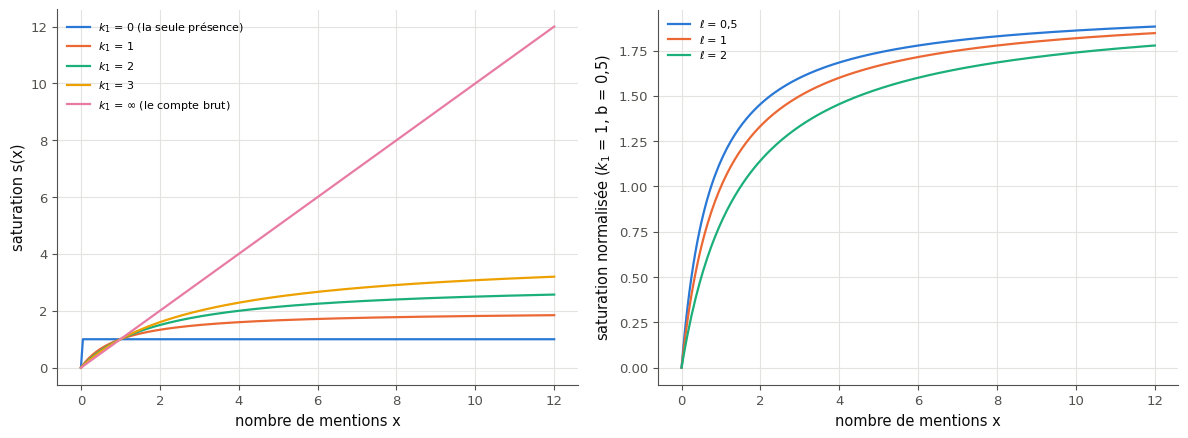

✅ Ex MB4.11 : ta saturation et tes deux figures sont justes, sur les appels du notebook et sur des appels cachés.


In [27]:
for letter, answer in zip("abcd", [answer_MB4_11a, answer_MB4_11b, answer_MB4_11c, answer_MB4_11d]):
    check_answer(f"MB4.11{letter}", answer)

HIDDEN_C11 = {'x': [0.0, 0.4, 1.0, 2.5, 7.0, 31.0],
 'k1': [0, 0.7, 2.5, math.inf],
 'id_s': 'MB4.11e',
 'draw_k1': [0.7, 2.5, math.inf],
 'draw_xmax': 9,
 'id_l': 'MB4.11f',
 'k1_l': 2,
 'b_l': 0.25,
 'ells': [0.6, 3],
 'xmax_l': 15,
 'id_h': 'MB4.11g',
 'idx': [0, 8, 16, 24, 32, 40, 56, 72, 80, 88, 104, 112, 120, 128, 144, 152, 160, 168, 176, 184, 192, 200, 208,
         216, 224, 240]}   # hidden arguments, and the sub-IDs of the values expected

_NAMES_C11 = r"(?:k_?\{?1\}?|k₁|k1|\\nu|ν|nu|\bb)"


def label_value_c11(label, drop):
    """The first number written in a label of the legend (½ is 0.5, ∞ or inf is the infinity), after the names k₁ and,
    for drop=True, the parameters k₁ = …, b = … and ν = … with their values are set aside; None when there is none."""
    text = str(label)
    if not text or text.startswith("_"):
        return None
    text = re.sub(r"\\frac\{(\d+)\}\{(\d+)\}", r" \1/\2 ", text)
    text = text.replace("½", " 0.5 ").replace("¼", " 0.25 ").replace("¾", " 0.75 ").replace(",", ".")
    if drop:
        text = re.sub(_NAMES_C11 + r"\s*(?:=|:)\s*[-+]?[\d.]+(?:/\d+)?", " ", text)
    text = re.sub(r"k_?\{?1\}?|k₁|k1", " ", text)
    match = re.search(r"(∞|\binf(?:ty|ini|inity)?\b)|(?<![\w.])(\d+(?:\.\d+)?)(?:/(\d+))?", text,
                      flags=re.IGNORECASE)
    if match is None:
        return None
    if match.group(1):
        return math.inf
    return float(match.group(2)) / float(match.group(3) or 1)


def legend_names_c11(ax, grid, curves, values, drop):
    """True when each curve (drawn at grid) is a line of ax whose label names its value first."""
    for curve, value in zip(curves, values):
        found = False
        for line in ax.lines:
            x, y = np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)
            if x.shape == grid.shape and y.shape == grid.shape and np.allclose(x, grid) \
                    and np.allclose(y, curve, equal_nan=True):
                named = label_value_c11(line.get_label(), drop)
                found = found or (named is not None and (named == value or math.isclose(named, value)))
        if not found:
            return False
    return True


def curves_why_c11(ax, values, xmax, curves, right, what, name):
    """What is wrong in a call of a drawing function (French phrases); right(curves) tells whether the curves returned
    are the right ones."""
    if not isinstance(curves, (list, tuple)) or len(curves) != len(values):
        return [f"{what} doit rendre la liste des {len(values)} tableaux tracés (un par valeur), reçu {shown(curves)}"]
    grid = np.linspace(0, xmax, 241)
    curves = [as_floats(c) for c in curves]
    if any(c is None or c.shape != grid.shape for c in curves):
        return [f"chaque tableau rendu par {what} doit avoir 241 valeurs, une par point de np.linspace(0, xmax, 241)"]
    problems = []
    if not right(curves):
        problems.append(f"les tableaux rendus doivent être les courbes de chaque {name} reçu, dans l'ordre reçu")
    if not all(line_with(ax, grid, c) for c in curves):
        problems.append("chaque courbe doit être tracée en fonction des 241 points de [0, xmax], np.linspace(0, xmax, 241)")
    if ax.get_legend() is None:
        problems.append("il faut une légende (label=…, puis ax.legend())")
    elif not legend_names_c11(ax, grid, curves, values, drop=(name == "ℓ")):
        problems.append(f"la légende doit nommer le {name} de chaque courbe (label=f\"{name} = {{valeur}}\")")
    if not ax.get_xlabel() or not ax.get_ylabel():
        problems.append("il faut des noms d'axes")
    return problems


with checked("MB4.11"):
    results_11 = []
    report_11 = reporter(results_11, stop=False)
    x_c11 = np.array(HIDDEN_C11["x"])                          # non-dyadic floats: a change in place would show
    got_c11, changed_c11 = [], False
    for k1_c11 in HIDDEN_C11["k1"]:
        received_c11 = x_c11.copy()
        got_c11.append(as_floats(call_safely("Ex MB4.11 : saturation_11 (appel caché)", saturation_11, received_c11,
                                             k1_c11)))
        changed_c11 = changed_c11 or not np.array_equal(received_c11, x_c11)
    if changed_c11:
        report_11(False, "", "saturation_11 modifie le tableau x reçu : calcule sur une copie")
    elif any(g is None or g.shape != x_c11.shape for g in got_c11):
        report_11(False, "", "saturation_11 rend un tableau de la forme de x")
    else:
        report_11(passes(HIDDEN_C11["id_s"], [g.tolist() for g in got_c11]),
                  "saturation_11 : des appels cachés (d'autres x, d'autres k₁, dont 0 et l'infini) sont justes",
                  "saturation_11 sur des appels cachés : ce n'est pas s(x) = x(k₁ + 1)/(x + k₁) ; relis les deux cas à "
                  "part, k₁ = 0 (la seule présence) et k₁ infini (le compte brut)")

    def saturations_right_c11(k1s, xmax):
        grid = np.linspace(0, xmax, 241)
        return lambda curves: all(matches(c, saturation_11(grid.copy(), k1), rtol=1e-9, atol=1e-12)
                                  for c, k1 in zip(curves, k1s))

    def lengths_right_c11(sub_id):
        return lambda curves: passes(sub_id, [c[HIDDEN_C11["idx"]].tolist() for c in curves])

    fig_11, axes_11 = plt.subplots(1, 2, figsize=(12, 4.5))
    try:
        drawn_11 = []
        opened_11 = drawn(lambda: drawn_11.append(call_safely("Ex MB4.11 : draw_saturations_11", draw_saturations_11,
                                                              axes_11[0], (0, 1, 2, 3, np.inf), 12)))
        problems_11 = curves_why_c11(axes_11[0], (0, 1, 2, 3, math.inf), 12, drawn_11[0],
                                     saturations_right_c11((0, 1, 2, 3, np.inf), 12), "draw_saturations_11", "k₁")
        report_11(not problems_11, "draw_saturations_11 (k₁ = 0, 1, 2, 3 et l'infini, sur [0, 12]) : les courbes, la "
                  "légende et les noms d'axes", "draw_saturations_11 : " + " ; ".join(problems_11))
        lengths_11 = []
        opened_11 += drawn(lambda: lengths_11.append(call_safely("Ex MB4.11 : draw_lengths_11", draw_lengths_11,
                                                                 axes_11[1], 1, 0.5, (0.5, 1, 2), 12)))
        problems_11 = curves_why_c11(axes_11[1], (0.5, 1, 2), 12, lengths_11[0], lengths_right_c11(HIDDEN_C11["id_l"]),
                                     "draw_lengths_11", "ℓ")
        report_11(not problems_11, "draw_lengths_11 (k₁ = 1, b = ½, ℓ = ½, 1 et 2, sur [0, 12]) : les courbes, la "
                  "légende et les noms d'axes", "draw_lengths_11 : " + " ; ".join(problems_11))
        fig_c11, axes_c11 = plt.subplots(1, 3)          # the 3rd axes is the current one: plt.plot would draw there
        try:
            hidden_s_c11, hidden_l_c11 = [], []
            opened_11 += drawn(lambda: hidden_s_c11.append(call_safely(
                "Ex MB4.11 : draw_saturations_11 (appel caché)", draw_saturations_11, axes_c11[0],
                tuple(HIDDEN_C11["draw_k1"]), HIDDEN_C11["draw_xmax"])))
            problems_c11 = curves_why_c11(axes_c11[0], HIDDEN_C11["draw_k1"], HIDDEN_C11["draw_xmax"], hidden_s_c11[0],
                                          saturations_right_c11(HIDDEN_C11["draw_k1"], HIDDEN_C11["draw_xmax"]),
                                          "draw_saturations_11", "k₁")
            opened_11 += drawn(lambda: hidden_l_c11.append(call_safely(
                "Ex MB4.11 : draw_lengths_11 (appel caché)", draw_lengths_11, axes_c11[1], HIDDEN_C11["k1_l"],
                HIDDEN_C11["b_l"], tuple(HIDDEN_C11["ells"]), HIDDEN_C11["xmax_l"])))
            problems_c11 += curves_why_c11(axes_c11[1], HIDDEN_C11["ells"], HIDDEN_C11["xmax_l"], hidden_l_c11[0],
                                           lengths_right_c11(HIDDEN_C11["id_h"]), "draw_lengths_11", "ℓ")
            elsewhere_11 = bool(axes_c11[2].lines or axes_c11[2].collections or axes_c11[2].get_legend())
        finally:
            plt.close(fig_c11)
        report_11(not problems_c11, "des appels cachés (d'autres k₁, d'autres longueurs, un autre b) sont justes aussi",
                  "des appels cachés (d'autres k₁, d'autres longueurs, un autre b) : "
                  + " ; ".join(dict.fromkeys(problems_c11)))
        report_11(not opened_11 and not elsewhere_11, "tes fonctions dessinent dans les axes reçus",
                  "tes fonctions doivent dessiner dans les axes reçus (ax.plot, ax.legend…), sans ouvrir de figure ni "
                  "dessiner dans l'axe courant (plt.plot, plt.legend…)")
    except BaseException:
        plt.close(fig_11)
        raise
    fig_11.tight_layout()
    plt.show()
    verdict("MB4.11", all(results_11) and len(results_11) == 5, "ta saturation et tes deux figures sont justes, sur les "
            "appels du notebook et sur des appels cachés.", "relis les lignes ❌ ci-dessus.")

**Ce qu'il faut regarder** : entre quelles deux courbes extrêmes se placent les autres ? Que fait une fiche longue à sa courbe, et une fiche courte ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 `saturation_11` : `(x > 0).astype(float)` pour $k_1 = 0$, `x.copy()` pour $k_1$ infini, sinon `x * (k1 + 1) / (x + k1)`. a) $(1{,}714286 ;\ 2{,}25 ;\ 2{,}666667)$. b) $(9, 18, 27)$ : $s(x) = 0{,}9(k_1 + 1)$ pour $x = 9k_1$. c) $(1{,}684211 ;\ 1{,}6 ;\ 1{,}454545)$. d) Vrai.

## Partie C · Déboguer

Fiche §1, §3 et §5. Trois erreurs classiques à corriger, qui passent une vérification mal choisie.

### Ex MB4.12 — Chasse à l'erreur : C pris dans la forme réduite au lieu de M, un classement lu comme la liste des rangs des candidats, un poids de rareté écrit ln(n/N) 🐛 ★ ⏱️ 15 min
**Objectif :** reconnaître trois erreurs classiques (C pris dans la forme réduite, un classement lu comme la liste des rangs, un poids de rareté de signe faux), qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §1, §3 et §5 ; Ex MB4.1, MB4.3 et MB4.4 · **Parcours :** C

Un collègue a écrit trois fonctions, chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `rank_factorization_bad(M)` doit rendre la factorisation par les colonnes pivots ; elle prend $\mathbf{C}$ dans les colonnes pivots de la **forme réduite** au lieu de celles de $\mathbf{M}$. Il l'a vérifiée sur une matrice déjà sous forme échelonnée réduite.
2. `borda_bad(rankings)` doit rendre les points de Borda ; elle lit chaque ligne comme la liste des **rangs** des candidats (la valeur d'indice $c$ comme la position du candidat $c$), au lieu de la liste des candidats dans l'ordre. Il l'a vérifiée sur trois jurys, `[[1, 0, 2], [0, 2, 1], [2, 1, 0]]`.
3. `rarity_bad(n, N)` doit rendre la surprise d'un ingrédient présent dans $n$ fiches sur $N$ ; elle rend $\ln\frac nN$. Il l'a vérifiée sur un ingrédient présent dans toutes les fiches, de poids nul.

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `rank_factorization_fixed`, `borda_fixed` et `rarity_fixed`, avec les mêmes arguments (sans `mymath` ; `exact_rref_12` de la cellule fournie reste permise). Le notebook fournit `RANK_12`, les classements de 4 juges et 6 candidats. Puis réponds :
- a) pour le tableau `M_1` des boulangeries, le plus grand écart $\lvert(\mathbf{C}\mathbf{F})_{ij} - M_{ij}\rvert$ par la fonction corrigée, puis par la fonction fautive (une liste de 2 nombres) ;
- b) pour `RANK_12`, les points de Borda par la fonction corrigée, puis par la fonction fautive (une liste de 2 listes de 6 entiers) ;
- c) les surprises d'ingrédients présents dans 3 et dans 30 fiches sur 90, par la fonction corrigée, puis par la fonction fautive (une liste de 4 nombres).

Dans ta copie : pour chacune des trois erreurs, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie aussi tes fonctions corrigées sur des cas cachés : d'autres tableaux, dont des tableaux de rang 1 et des tableaux dont les colonnes pivots ne sont pas les premières, des classements dont aucune ligne n'est sa propre inverse, et d'autres carnets.

In [28]:
import sympy as sp

RANK_12 = np.array([[4, 0, 1, 2, 3, 5], [2, 4, 5, 0, 1, 3], [4, 0, 5, 1, 2, 3], [0, 4, 1, 2, 3, 5]])   # 4 judges rank 6 candidates (0 to 5), best first
RANK_12.setflags(write=False)


# The colleague's code
def exact_rref_12(M):
    """The reduced row echelon form of M, computed exactly (SymPy, the entries read as decimal fractions), as an array
    of floats, and the list of its pivot columns."""
    R, pivots = sp.Matrix([[sp.Rational(str(x)) for x in row] for row in np.asarray(M, dtype=float)]).rref()
    return np.array(R, dtype=float), list(pivots)


def rank_factorization_bad(M):
    """The rank factorization (C, F) of M: C the pivot columns of M, F the non-zero rows of its reduced form."""
    R, pivots = exact_rref_12(M)
    return R[:, pivots], R[:len(pivots)]


def borda_bad(rankings):
    """The Borda points of complete rankings (each row lists the candidates, best first)."""
    R = np.asarray(rankings)
    m, n = R.shape
    points = np.zeros(n, dtype=int)
    for row in R:
        for c in range(n):
            points[c] += n - 1 - row[c]
    return points


def rarity_bad(n, N):
    """The surprise of an ingredient found in n recipe cards out of N."""
    return math.log(n / N)


# The colleague's checks: all pass
E_12 = np.array([[1.0, 0, 5, 0, -2], [0, 1, 3, 0, 4], [0, 0, 0, 1, 7]])   # a matrix already in reduced row echelon form
C_12, F_12 = rank_factorization_bad(E_12)
print("(1)", bool(np.allclose(C_12 @ F_12, E_12)), "(attendu True : C F redonne la matrice)")
print("(2)", borda_bad([[1, 0, 2], [0, 2, 1], [2, 1, 0]]).tolist() == [3] * 3,
      "(attendu True : trois jurys, trois points chacun, à la main)")
print("(3)", rarity_bad(90, 90) == 0, "(attendu True : un ingrédient présent dans toutes les fiches ne surprend pas)")

(1) True (attendu True : C F redonne la matrice)
(2) True (attendu True : trois jurys, trois points chacun, à la main)
(3) True (attendu True : un ingrédient présent dans toutes les fiches ne surprend pas)


In [29]:
def rank_factorization_fixed(M):
    """The rank factorization (C, F) of M: C the pivot columns of M, F the non-zero rows of its reduced form."""
    R, pivots = exact_rref_12(M)
    return np.asarray(M, dtype=float)[:, pivots], R[:len(pivots)]     # the columns of M itself, not of R


def borda_fixed(rankings):
    """The Borda points of complete rankings (each row lists the candidates, best first)."""
    R = np.asarray(rankings)
    m, n = R.shape
    points = np.zeros(n, dtype=int)
    for row in R:
        for p, c in enumerate(row):                                    # the candidate c is at the position p
            points[c] += n - 1 - p
    return points


def rarity_fixed(n, N):
    """The surprise of an ingredient found in n recipe cards out of N."""
    return -math.log(n / N)                                            # ln(N / n) > 0 for n < N


answer_MB4_12a = [float(np.max(np.abs(np.matmul(*rank_factorization_fixed(M_1)) - M_1))),
                  float(np.max(np.abs(np.matmul(*rank_factorization_bad(M_1)) - M_1)))]
answer_MB4_12b = [borda_fixed(RANK_12).tolist(), borda_bad(RANK_12).tolist()]
answer_MB4_12c = [rarity_fixed(3, 90), rarity_fixed(30, 90), rarity_bad(3, 90), rarity_bad(30, 90)]
print("a)", answer_MB4_12a, " b)", answer_MB4_12b, " c)", np.round(answer_MB4_12c, 6).tolist())

a) [0.0, 19.0]  b) [[15, 9, 10, 2, 18, 6], [10, 12, 8, 15, 11, 4]]  c) [3.401197, 1.098612, -3.401197, -1.098612]


In [30]:
import sympy as sp_12r

sales_12r = sp_12r.Matrix([[20, 6, 16, 12, 8], [8, 10, 14, 20, 7], [12, 4, 10, 8, 5], [16, 2, 10, 4, 5]])
form_12r, pivots_12r = sales_12r.rref()
right_a_12r = float(max(abs(x) for x in sales_12r[:, list(pivots_12r)] * form_12r[:len(pivots_12r), :] - sales_12r))
bad_a_12r = float(max(abs(x) for x in form_12r[:, list(pivots_12r)] * form_12r[:len(pivots_12r), :] - sales_12r))
wbm.record("MB4.12a", [right_a_12r, bad_a_12r], decimals=6,
           mistakes={"rank_factorization_fixed prend encore C dans la forme réduite : C est faite des colonnes pivots de M "
                     "elle-même": [bad_a_12r, bad_a_12r],
                     "le second nombre est celui de la version FAUSSE, rank_factorization_bad": [right_a_12r, right_a_12r],
                     "la version corrigée d'abord, puis la version fautive": [bad_a_12r, right_a_12r]})
judges_12r = np.array([[4, 0, 1, 2, 3, 5], [2, 4, 5, 0, 1, 3], [4, 0, 5, 1, 2, 3], [0, 4, 1, 2, 3, 5]])
inverse_12r = np.argsort(judges_12r, axis=1)                          # the oracle: the position of each candidate
right_b_12r = (judges_12r.shape[1] - 1 - inverse_12r).sum(axis=0).tolist()
bad_b_12r = (judges_12r.shape[1] - 1 - judges_12r).sum(axis=0).tolist()
wbm.record("MB4.12b", [right_b_12r, bad_b_12r],
           mistakes={"borda_fixed lit encore chaque ligne comme la liste des rangs : une ligne est un ordre, le candidat "
                     "placé à chaque position": [bad_b_12r, bad_b_12r],
                     "la seconde liste est celle de la version FAUSSE, borda_bad": [right_b_12r, right_b_12r],
                     "la version corrigée d'abord, puis la version fautive": [bad_b_12r, right_b_12r]})
right_c_12r, bad_c_12r = [math.log(90 / n) for n in (3, 30)], [-math.log(90 / n) for n in (3, 30)]
wbm.record("MB4.12c", right_c_12r + bad_c_12r, decimals=6,
           mistakes={"rarity_fixed rend encore ln(n/N), négatif pour un ingrédient rare": bad_c_12r + bad_c_12r,
                     "les deux derniers nombres sont ceux de la version FAUSSE, rarity_bad": right_c_12r + right_c_12r,
                     "la version corrigée d'abord, puis la version fautive": bad_c_12r + right_c_12r,
                     "la surprise se mesure avec le logarithme népérien, en nats":
                         [math.log10(90 / n) for n in (3, 30)] + bad_c_12r})
CASES_12r = {'tables': [[[0.0, 0.3, 0.6, -0.9], [0.0, 0.7, 1.4, -2.1], [0.0, -1.1, -2.2, 3.3]],
            [[1.3, -1.95, 0.4, 2.1, 0.25], [0.2, -0.3, 1.1, 2.4, -1.0], [-0.7, 1.05, 0.9, 1.1, -1.25],
             [2.1, -3.15, -0.6, 0.9, 1.65]],
            [[0.9, 0.5, 0.4, -0.3], [-0.4, 1.6, -2.0, 0.6], [1.7, -0.8, 2.5, 1.4], [0.3, 2.2, -1.9, -0.5],
             [-1.2, 0.1, -1.3, 0.8]]],
 'rankings': [[[5, 3, 0, 2, 1, 6, 4], [2, 3, 1, 6, 4, 5, 0], [0, 1, 5, 6, 3, 4, 2], [0, 3, 5, 1, 6, 4, 2],
               [4, 3, 2, 5, 0, 6, 1]],
              [[3, 2, 4, 1, 0], [4, 1, 2, 0, 3], [2, 3, 4, 1, 0]],
              [[3, 1, 5, 6, 7, 2, 0, 4], [3, 6, 0, 7, 5, 2, 1, 4], [4, 3, 1, 2, 6, 7, 0, 5],
               [2, 6, 1, 5, 7, 4, 0, 3], [7, 2, 6, 0, 5, 3, 1, 4], [7, 2, 4, 6, 3, 5, 0, 1]]],
 'notebooks': [[7, 120], [33, 61], [250, 400], [1, 13]],
 'id': 'MB4.12d'}                                                   # the hidden notebooks of recipes of the check
wbm.record(CASES_12r["id"], [math.log(N / n) for n, N in CASES_12r["notebooks"]], decimals=6)

WBM_ANSWER {"decimals": 6, "element_coarse": [["ee95526a2ff11de7aee2d97a68128e283215e6ba7aabd4d89a30e470bcb52236"], ["684e2ef5758a99eb009ee76b3b29ca45e9e7b954b0651c11ea40856ebf4f898c"]], "element_coarse_any": [[], ["297236548933b0e0f98dce5bae2b54856f7fba97956dc020f9943c8d6f4817c4", "2b7a472364173b59f74517bee5047ed6c6ef2ba5c2a033a5732a58a9c121d02e", "96c683e0a424f8bb4f48848d1a3e206a84e9d719821407bb953486477c27c724", "30199ca7b311f53181775a479a37fe1a65981d61acbfc7f9d18ce99bb7753579", "15eef851a1168ffb9f49c89857108e22269fc0d914f99674bf7543611e5258e8"]], "element_hashes": ["4e5d17350daa4317b2005f6437497eeaf1232a8b15f5e8235ab1afd1f840efc0", "58c3dce4f9cba389561253d5e4357a3ac62bf5f66f89e710c6a96d6198c3f4cf"], "hash": "714f280630301cf5d1985e81c8c970f101d1a8aae6f78d8d57cc1431535df385", "id": "MB4.12a", "kind": "array", "mistakes": {"6d3ded21e7c11e82ba5d3d6396330a03927c869464bd2cecca2c5d1c79fbde0a": "la version corrigée d'abord, puis la version fautive", "7e95c7f691beff1a9b46f791bec65bb36817537

In [31]:
for letter, answer in zip("abc", [answer_MB4_12a, answer_MB4_12b, answer_MB4_12c]):
    check_answer(f"MB4.12{letter}", answer)

CASES_C12 = {'tables': [[[0.0, 0.3, 0.6, -0.9], [0.0, 0.7, 1.4, -2.1], [0.0, -1.1, -2.2, 3.3]],
            [[1.3, -1.95, 0.4, 2.1, 0.25], [0.2, -0.3, 1.1, 2.4, -1.0], [-0.7, 1.05, 0.9, 1.1, -1.25],
             [2.1, -3.15, -0.6, 0.9, 1.65]],
            [[0.9, 0.5, 0.4, -0.3], [-0.4, 1.6, -2.0, 0.6], [1.7, -0.8, 2.5, 1.4], [0.3, 2.2, -1.9, -0.5],
             [-1.2, 0.1, -1.3, 0.8]]],
 'rankings': [[[5, 3, 0, 2, 1, 6, 4], [2, 3, 1, 6, 4, 5, 0], [0, 1, 5, 6, 3, 4, 2], [0, 3, 5, 1, 6, 4, 2],
               [4, 3, 2, 5, 0, 6, 1]],
              [[3, 2, 4, 1, 0], [4, 1, 2, 0, 3], [2, 3, 4, 1, 0]],
              [[3, 1, 5, 6, 7, 2, 0, 4], [3, 6, 0, 7, 5, 2, 1, 4], [4, 3, 1, 2, 6, 7, 0, 5],
               [2, 6, 1, 5, 7, 4, 0, 3], [7, 2, 6, 0, 5, 3, 1, 4], [7, 2, 4, 6, 3, 5, 0, 1]]],
 'notebooks': [[7, 120], [33, 61], [250, 400], [1, 13]],
 'id': 'MB4.12d'}   # the hidden tables, rankings and notebooks of recipes, and the sub-ID expected

results_12, parts_12 = [], []


def report_12(ok, success, failure):
    results_12.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_12(part, name, function, *args):
    """function(*args); an error of the learner's code becomes one ❌ line that names the function."""
    try:
        return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_12(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:160]}")
        parts_12.append(part)
        raise StopCheck from None


def factors_12(got):
    """(C, F) as two 2-D float arrays, or None when got is not such a pair."""
    try:
        C, F = got
        C, F = np.asarray(C, dtype=float), np.asarray(F, dtype=float)
    except (TypeError, ValueError):
        return None
    return (C, F) if C.ndim == 2 and F.ndim == 2 else None


with checked("MB4.12"):                                      # (1) rank_factorization_fixed
    wrong_c12 = []
    for table_c12 in CASES_C12["tables"]:
        M_c12 = np.array(table_c12)                          # non-dyadic floats: a change in place would show
        before_c12 = M_c12.copy()
        got_c12 = factors_12(call_12(1, "rank_factorization_fixed", rank_factorization_fixed, M_c12))
        want_c12 = ref_ranks.rank_factorization(before_c12)
        if not np.array_equal(M_c12, before_c12):
            wrong_c12.append("ta fonction modifie le tableau reçu : travaille sur une copie")
        elif got_c12 is None:
            wrong_c12.append("rank_factorization_fixed rend le couple (C, F) de deux tableaux 2-D")
        elif all(matches(g, w, rtol=1e-9, atol=1e-9) for g, w in zip(got_c12, want_c12)):
            continue
        elif matches(got_c12[0], rank_factorization_bad(before_c12)[0], atol=1e-9):
            wrong_c12.append("ta correction prend encore C dans la forme réduite : C est faite des colonnes pivots de M "
                             "elle-même")
        elif got_c12[0].shape == want_c12[0].shape and matches(got_c12[0], before_c12[:, :got_c12[0].shape[1]]):
            wrong_c12.append("sur des tableaux dont les colonnes pivots ne sont pas les premières, C n'est pas faite des "
                             "colonnes pivots de M")
        else:
            wrong_c12.append("sur d'autres tableaux (de rang 1, des colonnes pivots qui ne sont pas les premières), ce "
                             "n'est pas la factorisation par les colonnes pivots : C les colonnes pivots de M, F les "
                             "lignes non nulles de sa forme réduite")
    report_12(not wrong_c12, "(1) rank_factorization_fixed : des tableaux cachés, de rang 1 ou de colonnes pivots qui ne "
              "sont pas les premières", "(1) rank_factorization_fixed : " + " ; ".join(dict.fromkeys(wrong_c12)))
    parts_12.append(1)

with checked("MB4.12"):                                      # (2) borda_fixed, compared with the reference
    wrong_c12 = []
    for rankings_c12 in CASES_C12["rankings"]:
        R_c12 = np.array(rankings_c12)
        before_c12 = R_c12.copy()
        got_c12 = as_floats(call_12(2, "borda_fixed", borda_fixed, R_c12))
        want_c12 = ref_ranks.borda_scores(before_c12)
        if not np.array_equal(R_c12, before_c12):
            wrong_c12.append("ta fonction modifie le tableau reçu : travaille sur une copie")
        elif got_c12 is None or got_c12.shape != want_c12.shape:
            wrong_c12.append(f"borda_fixed rend un tableau de {before_c12.shape[1]} points, un par candidat")
        elif np.array_equal(got_c12, want_c12):
            continue
        elif np.array_equal(got_c12, borda_bad(before_c12)):
            wrong_c12.append("ta correction lit encore chaque ligne comme la liste des rangs des candidats : une ligne "
                             "est un ordre, le candidat placé à chaque position")
        else:
            wrong_c12.append("sur des classements dont aucune ligne n'est sa propre inverse, ce ne sont pas les points de "
                             "Borda : le candidat placé à la position p d'une ligne (à partir de 0) reçoit n − 1 − p "
                             "points")
    report_12(not wrong_c12, "(2) borda_fixed : des classements cachés, dont aucune ligne n'est sa propre inverse",
              "(2) borda_fixed : " + " ; ".join(dict.fromkeys(wrong_c12)))
    parts_12.append(2)

with checked("MB4.12"):                                      # (3) rarity_fixed
    got_c12 = [call_12(3, "rarity_fixed", rarity_fixed, n_c12, N_c12) for n_c12, N_c12 in CASES_C12["notebooks"]]
    numbers_c12 = as_floats(got_c12)
    if numbers_c12 is None or numbers_c12.shape != (len(got_c12),):
        why_c12 = f"rarity_fixed rend un nombre, reçu {shown(got_c12)}"
    elif passes(CASES_C12["id"], numbers_c12.tolist()):
        why_c12 = ""
    elif all(math.isclose(g, rarity_bad(n, N), abs_tol=1e-9) for g, (n, N) in zip(numbers_c12, CASES_C12["notebooks"])):
        why_c12 = "ta correction rend encore ln(n/N), négatif pour un ingrédient rare"
    else:
        why_c12 = ("sur d'autres carnets, ce n'est pas la surprise d'un ingrédient présent dans n fiches sur N, un nombre "
                   "positif, en nats")
    report_12(not why_c12, "(3) rarity_fixed : d'autres carnets", f"(3) rarity_fixed : {why_c12}")
    parts_12.append(3)

if len(set(parts_12)) == 3:
    verdict("MB4.12", all(results_12), "les trois fonctions corrigées passent tous les cas.", "relis les lignes ❌ ci-dessus.")

✅ Ex MB4.12a : Bien joué !
✅ Ex MB4.12b : C'est ça !
✅ Ex MB4.12c : Parfait !
✅ (1) rank_factorization_fixed : des tableaux cachés, de rang 1 ou de colonnes pivots qui ne sont pas les premières
✅ (2) borda_fixed : des classements cachés, dont aucune ligne n'est sa propre inverse
✅ (3) rarity_fixed : d'autres carnets
✅ Ex MB4.12 : les trois fonctions corrigées passent tous les cas.


**Après la vérification**, dans ta copie : pour chacune des trois erreurs, pourquoi la vérification du collègue ne la voyait-elle pas, et quelle vérification l'aurait vue ?

💡 (1) La forme réduite a l'identité dans ses colonnes pivots : prise pour $\mathbf{C}$, elle donne $\mathbf{C}\mathbf{F}$ = la forme réduite, pas $\mathbf{M}$ ; correction : `C = np.asarray(M, dtype=float)[:, pivots]`. a) $(0, 19)$. (2) Une ligne est un ordre ; correction : `points[row[p]] += n - 1 - p`. b) $(15, 9, 10, 2, 18, 6)$, puis $(10, 12, 8, 15, 11, 4)$. (3) Le signe : correction `-math.log(n / N)`. c) $(3{,}401197 ;\ 1{,}098612 ;\ -3{,}401197 ;\ -1{,}098612)$.

## Partie D · Défi

Fiche §2. Le rang caché de tableaux bruités, retrouvé par leurs valeurs singulières, vérifié sur des tableaux cachés tirés à chaque exécution.

### Ex MB4.13 — Défi : retrouver le rang caché de cinq tableaux bruités, cinq fois sur cinq, par leurs valeurs singulières 🏆 ★★★ ⏱️ 25 min
**Objectif :** retrouver le rang caché d'un tableau bruité en comparant ses valeurs singulières au niveau du bruit, estimé sur le tableau lui-même, et le vérifier sur des tableaux cachés.  
**Prérequis :** fiche §2 ; M12d (SVD, Eckart-Young) ; Ex MB4.2 · **Parcours :** C

Le notebook fournit `TABLES_13`, cinq tableaux de mesures de formes différentes. Chacun est la somme d'un tableau de rang $r$ (caché) et d'un bruit : chaque case reçoit un bruit indépendant, de moyenne nulle et de même écart-type $\sigma$ dans tout le tableau ; $\sigma$ change d'un tableau à l'autre, et n'est pas donné. Écris `hidden_rank_13(M)`, qui rend le rang caché d'un tableau (un entier $\ge 0$ : un tableau peut n'avoir aucun signal), en lisant ses valeurs singulières ; tout NumPy et SciPy sont permis (`np.linalg.svd(M, compute_uv=False)` donne les valeurs singulières).

**Critère de réussite** (les « cinq fois sur cinq » du titre) **:** le bon rang pour cinq tableaux cachés, tirés à nouveau à chaque exécution (l'un facile, l'un dont le signal dépasse à peine le bruit, l'un dont les valeurs singulières du signal s'étalent sur un facteur 10 ou plus, l'un très allongé, et l'un sans signal ou à une échelle extrême), en moins de 10 secondes en tout, et le bon rang pour les cinq tableaux du notebook : la vérification recalcule ta réponse a) avec ta fonction. Relève :
- a) les rangs que rend ta fonction pour les cinq tableaux (une liste de 5 entiers) ;
- b) `np.linalg.matrix_rank` de chacun (une liste de 5 entiers) ;
- c) le rang effectif à 99 % de chacun (une liste de 5 entiers).

Point de départ : le bruit seul a des valeurs singulières qui ne dépassent guère $\sigma(\sqrt m + \sqrt n)$ (fiche §2) ; $\sigma$ n'est pas donné, mais ce que le rang laisse de côté est presque tout du bruit, et tu sais ce que vaut son énergie (Eckart-Young).

In [32]:
def _tables_13():
    """The five tables of the notebook, read in solutions/challenges/mb4_13.py (the hidden part of the challenge: the law
    of the tables and their hidden ranks stay there; reading it spoils the challenge)."""
    import importlib.util
    spec = importlib.util.spec_from_file_location("mb4_13_tables",
                                                  wbm.repo_root() / "solutions" / "challenges" / "mb4_13.py")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return [np.array(table, dtype=float) for table in module.notebook_tables()]


TABLES_13 = _tables_13()   # five noisy tables of measurements: shapes (90, 60), (70, 110), (120, 120), (80, 50), (100, 75)
del _tables_13
for _array in TABLES_13:
    _array.setflags(write=False)
print("formes :", [table.shape for table in TABLES_13])

formes : [(90, 60), (70, 110), (120, 120), (80, 50), (100, 75)]


In [33]:
def hidden_rank_13(M):
    """The hidden rank of a noisy table M (an integer >= 0), read on its singular values."""
    M = np.asarray(M, dtype=float)
    m, n = M.shape
    s = np.linalg.svd(M, compute_uv=False)
    r = 0
    for _ in range(50):
        if r >= min(m, n):
            break
        sigma = math.sqrt(float(np.sum(s[r:] ** 2)) / ((m - r) * (n - r)))     # the noise, on what the rank leaves aside
        r_new = int(np.sum(s > 1.2 * sigma * (math.sqrt(m) + math.sqrt(n))))   # above the level of the noise
        if r_new == r:
            break
        r = r_new
    return r


def effective_rank_13(M, level=0.99):
    s = np.linalg.svd(M, compute_uv=False)
    return int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), level) + 1)


start_13 = time.perf_counter()
answer_MB4_13a = [hidden_rank_13(table) for table in TABLES_13]
answer_MB4_13b = [int(np.linalg.matrix_rank(table)) for table in TABLES_13]
answer_MB4_13c = [effective_rank_13(table) for table in TABLES_13]
print("a)", answer_MB4_13a, " b)", answer_MB4_13b, " c)", answer_MB4_13c, f" ({time.perf_counter() - start_13:.2f} s)")

a) [3, 1, 5, 2, 4]  b) [60, 70, 120, 50, 75]  c) [48, 62, 67, 43, 58]  (0.01 s)


In [34]:
import importlib.util as importlib_util_13r

spec_13r = importlib_util_13r.spec_from_file_location("mb4_13_record",
                                                      wbm.repo_root() / "solutions" / "challenges" / "mb4_13.py")
challenge_13r = importlib_util_13r.module_from_spec(spec_13r)
spec_13r.loader.exec_module(challenge_13r)
tables_13r = challenge_13r.notebook_tables()


def shares_13r(table, power=2):
    s = np.linalg.svd(table, compute_uv=False) ** power
    return np.cumsum(s) / np.sum(s)


wbm.record("MB4.13a", challenge_13r.notebook_ranks())
def numerical_rank_13r(table):
    """The oracle: the singular values above the default tolerance of np.linalg.matrix_rank, s1 max(m, n) eps."""
    s = np.linalg.svd(table, compute_uv=False)
    return int(np.sum(s > s[0] * max(table.shape) * np.finfo(float).eps))


wbm.record("MB4.13b", [numerical_rank_13r(t) for t in tables_13r],
           mistakes={"le rang ne dépasse pas le plus petit des deux côtés du tableau": [max(t.shape) for t in tables_13r]})
wbm.record("MB4.13c", [int(np.argmax(shares_13r(t) >= 0.99)) + 1 for t in tables_13r],
           mistakes={"le rang effectif à 99 % est le plus petit r dont la part atteint 0,99 : compte r à partir de 1":
                         [int(np.argmax(shares_13r(t) >= 0.99)) for t in tables_13r],
                     "l'énergie compte les carrés des valeurs singulières":
                         [int(np.argmax(shares_13r(t, power=1) >= 0.99)) + 1 for t in tables_13r]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a8d9875bdc64854480d368a30639a68530cb7bddc4ab7a53d9ccf7cf05f19c41", "fdd2d57b73efc6eccf0377ed035ab664b83f8fef98b55b4d13ad04f9a9f843df", "c4bc21141d44cf84495642c86660feb3317d0a531f8bc3f7421347e706f8721e", "3222996fdc4161ce3416b78a816efa4520adf501fccb6827998dfdef7e9626b8", "8cab85a19d0e3d9e524262e04546de9f8acd4c7e73fdd9591a6b53733a916b53"], "hash": "5d710d1ad62fbc65927748c0e68fb15e3b7e606fafdf226284355f80fed35be7", "id": "MB4.13a", "integer": true, "kind": "array", "shape": [5]}
📝 Ex MB4.13a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a9a713ab398469a1ff406a96bc20a099ab457d37f7745eaa2de23790d7301da5", "9d69d2dec0ccb77d5eba13241c58e8cc7c6f55ff8388dd6f009f2e3a042318ed", "95f06ac89b586ff85967911dcce2afaaf891591d2030f2dcd5af753f3168373a", "840a0ff801b1f7b83068abf3217343d2c3632d1ba5e3f35220533541784c50fb", "713070e5d73826702b4408ad629cfe23466ec2076b8edcb17751383e68d34b83"], "hash": "094f8f7709c2fa5bf1a5

In [35]:
for letter, answer in zip("bc", [answer_MB4_13b, answer_MB4_13c]):
    check_answer(f"MB4.13{letter}", answer)

def check_c13():
    """The check of MB4.13, in a function: the hidden tables and their ranks stay local, and each hidden rank is read
    only after hidden_rank_13 has returned."""
    import importlib.util
    spec = importlib.util.spec_from_file_location("mb4_13_challenge",
                                                  wbm.repo_root() / "solutions" / "challenges" / "mb4_13.py")
    challenge = importlib.util.module_from_spec(spec)   # the hidden part of the challenge: the law of the hidden tables
    spec.loader.exec_module(challenge)                  # and the method of the check (reading it spoils the challenge)
    results, elapsed = [], [0.0]
    report = reporter(results, stop=False)

    def rank_of(label, M):
        start = time.perf_counter()
        got = call_safely(label, hidden_rank_13, M.copy())
        elapsed[0] += time.perf_counter() - start
        if isinstance(got, (bool, np.bool_)) or not isinstance(got, (int, np.integer)) or got < 0:
            print(f"❌ {label} : hidden_rank_13 rend un entier ≥ 0 (un int), reçu {shown(got)}")
            raise StopCheck
        return int(got)

    found = [rank_of(f"Ex MB4.13 : hidden_rank_13 (tableau {k} du notebook)", table)
             for k, table in enumerate(TABLES_13, start=1)]
    report(passes("MB4.13a", found), "les cinq tableaux du notebook : les cinq rangs cachés",
           "les cinq tableaux du notebook : ta fonction ne retrouve pas tous les rangs cachés ; compare chaque valeur "
           "singulière au niveau du bruit, que tu estimes sur le tableau lui-même")
    if not filled(answer_MB4_13a):
        print("⏳ Ex MB4.13a : pas encore fait.")
    else:
        mine = as_floats(answer_MB4_13a)
        report(mine is not None and mine.shape == (5,) and mine.tolist() == found,
               "Ex MB4.13a : ta réponse est ce que rend ta fonction sur les cinq tableaux",
               "Ex MB4.13a : ta réponse n'est pas ce que rend hidden_rank_13 sur les cinq tableaux de TABLES_13 "
               "maintenant (la vérification les recalcule) : exécute à nouveau ta cellule")
    rng = np.random.default_rng()                              # at each run: five new hidden tables, one of each kind
    kinds = list(challenge.KINDS)
    rng.shuffle(kinds)
    for k, kind in enumerate(kinds, start=1):
        seed = int(rng.integers(2 ** 62))
        M = challenge.hidden_table(np.random.default_rng(seed), kind)[0]
        got = rank_of(f"Ex MB4.13 : hidden_rank_13 (tableau caché {k})", M)
        rank = challenge.hidden_table(np.random.default_rng(seed), kind)[1]       # read after the call
        where = f"tableau caché {k} ({kind}, {M.shape[0]} × {M.shape[1]})"
        report(got == rank, f"{where} : le bon rang",
               f"{where} : rendu {got}, alors que le rang caché est {rank} ; un seuil fixe ou une part d'énergie ne suit "
               "pas un bruit dont l'échelle change d'un tableau à l'autre")
    report(elapsed[0] < 10, f"en {fr(elapsed[0], 2)} s pour les dix tableaux",
           f"trop lent : {fr(elapsed[0], 1)} s pour les dix tableaux, il faut moins de 10 s")
    verdict("MB4.13", all(results) and len(results) >= 7, "critère atteint : le bon rang pour les cinq tableaux du "
            "notebook et pour cinq tableaux cachés, en moins de 10 secondes.",
            "critère pas encore atteint : relis les lignes ❌ ci-dessus.")


with checked("MB4.13"):
    check_c13()

✅ Ex MB4.13b : Parfait !
✅ Ex MB4.13c : Bravo !
✅ les cinq tableaux du notebook : les cinq rangs cachés
✅ Ex MB4.13a : ta réponse est ce que rend ta fonction sur les cinq tableaux
✅ tableau caché 1 (sans signal ou échelle extrême, 34 × 180) : le bon rang
✅ tableau caché 2 (allongé, 31 × 260) : le bon rang
✅ tableau caché 3 (facile, 192 × 102) : le bon rang
✅ tableau caché 4 (signal faible, 72 × 274) : le bon rang
✅ tableau caché 5 (étalé, 67 × 210) : le bon rang
✅ en 0,01 s pour les dix tableaux
✅ Ex MB4.13 : critère atteint : le bon rang pour les cinq tableaux du notebook et pour cinq tableaux cachés, en moins de 10 secondes.


**Pour réfléchir** : pourquoi b) et c) ne trouvent-ils pas le rang caché ? Pourquoi une tolérance ou un seuil choisis sur les cinq tableaux du notebook ne suffisent-ils pas pour les tableaux cachés ? Les réponses sont dans `05_solutions.md`, section Notebook.

💡 a) $(3, 1, 5, 2, 4)$ ; b) $(60, 70, 120, 50, 75)$, le rang plein ; c) $(48, 62, 67, 43, 58)$. La méthode ci-dessus estime le bruit sur ce que le rang laisse de côté, $\hat\sigma^2 = \sum_{i > r}s_i^2/((m - r)(n - r))$, compte les $s_i$ au-dessus de $1{,}2\,\hat\sigma(\sqrt m + \sqrt n)$, et recommence jusqu'à ce que $r$ ne change plus. Le piège : ni une tolérance fixe ni une part d'énergie ne savent où s'arrête le bruit, dont l'échelle change d'un tableau à l'autre.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu factoriser une matrice de rang $r$ par ses colonnes pivots, en trouver une autre factorisation, et compter les nombres stockés et libres ?
2. Sais-tu mesurer le rang effectif et le rang stable d'un tableau mesuré, et appliquer une matrice factorisée dans l'ordre le moins coûteux ?
3. Sais-tu calculer le poids d'un indice rare, et dire quand le poids corrigé devient négatif ?
4. Sais-tu étudier la saturation et la normalisation par la longueur, et prévoir l'effet de $k_1$ et de $b$ ?
5. Sais-tu fusionner des classements par Borda et par la somme des $\frac{1}{c + \text{rang}}$, et dire pourquoi ces fusions ne dépendent pas des échelles ?
6. Sais-tu calculer recall@k, precision@k et le MRR, et leur valeur pour un ordre tiré au hasard ?

**La suite** : le chapitre bonus B4 de workbookIA, qui applique ces outils.